In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import cohen_kappa_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from itertools import combinations
from collections import Counter


# configure paths 
# 
DATASET_DIR = Path("/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development")
FEATURES_DIR = DATASET_DIR / "audio_features"

# Collect all npz file paths
npz_files = sorted(FEATURES_DIR.glob("*.npz"))
print(f"Found {len(npz_files)} npz files")


# set binarization parameters 
BINARIZE_THRESH = 0.5
# Each time step is 1 second (features aggregated over 1-second windows)
TIME_STEP_SEC = 1.0


Found 3656 npz files


In [51]:
# ── Load all npz files into a list of dicts ──
records = []
for npz_path in npz_files:
    data = dict(np.load(npz_path, allow_pickle=True))
    file_id = npz_path.stem  # e.g. "000001"

    records.append({
        "file_id":           file_id,
        "annotations":       data["annotations"],            # [T, C, A]
        "class_names":       list(data["class_names"]),       
        "annotator_ids":     list(data["annotator_ids"]),    
        "is_own_recording":  list(data["is_own_recording"]), 
        "target_classes":    list(data["target_classes"]),    
        "non_target_classes":list(data["non_target_classes"]),
    })
     
CLASS_NAMES = records[0]["class_names"]
NUM_CLASSES = len(CLASS_NAMES)

print(f"Loaded {len(records)} recordings")
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Example annotation shape: {records[0]['annotations'].shape}")

Loaded 3656 recordings
Classes (15): ['bell_ringing', 'coffee_machine', 'cutlery_dishes', 'door_open_close', 'footsteps', 'keyboard_typing', 'keychain', 'light_switch', 'microwave', 'phone_ringing', 'running_water', 'toilet_flushing', 'vacuum_cleaner', 'wardrobe_drawer_open_close', 'window_open_close']
Example annotation shape: (61, 15, 2)


In [40]:
records

[{'file_id': '000001',
  'annotations': array([[[0., 0.],
          [0., 0.],
          [0., 0.],
          ...,
          [0., 0.],
          [0., 0.],
          [0., 0.]],
  
         [[0., 0.],
          [0., 0.],
          [0., 0.],
          ...,
          [0., 0.],
          [0., 0.],
          [0., 0.]],
  
         [[0., 0.],
          [0., 0.],
          [0., 0.],
          ...,
          [0., 0.],
          [0., 0.],
          [0., 0.]],
  
         ...,
  
         [[0., 0.],
          [0., 0.],
          [0., 0.],
          ...,
          [0., 0.],
          [0., 0.],
          [0., 0.]],
  
         [[0., 0.],
          [0., 0.],
          [0., 0.],
          ...,
          [0., 0.],
          [0., 0.],
          [0., 0.]],
  
         [[0., 0.],
          [0., 0.],
          [0., 0.],
          ...,
          [0., 0.],
          [0., 0.],
          [0., 0.]]], shape=(61, 15, 2), dtype=float32),
  'class_names': ['bell_ringing',
   'coffee_machine',
   'cutlery_dishes',
  

# 2- Annotations 

### (a) Annotator Agreement: Binarize per-annotator, compute pairwise Cohen's Kappa
#### The idea: for each file and each annotator pair, we binarize their annotation vectors (threshold > 0.5 → active) and compute Cohen's Kappa per class and overall. We then aggregate across all files.

In [ ]:
# # ── 2a Only compute kappa for a class in files where
# #    at least one annotator marked it present ──


# classwise_kappas = {c: [] for c in CLASS_NAMES}
# overall_kappas = []

# for rec in records:
#     ann = rec["annotations"]  # [T, C, A]
#     T, C, A = ann.shape
#     if A < 2:
#         continue

#     ann_bin = (ann > BINARIZE_THRESH).astype(int)

#     for i, j in combinations(range(A), 2):
#         # ── Per-class kappa (only if class is relevant in this file) ──
#         for c_idx, c_name in enumerate(CLASS_NAMES):
#             y_i = ann_bin[:, c_idx, i]
#             y_j = ann_bin[:, c_idx, j]

#             # Skip if BOTH annotators marked all-zero → trivial agreement
#             if y_i.sum() == 0 and y_j.sum() == 0:
#                 continue

#             if len(np.unique(y_i)) == 1 and len(np.unique(y_j)) == 1:
#                 # One is all-1, the other all-0 → complete disagreement
#                 kappa = 0.0
#             else:
#                 kappa = cohen_kappa_score(y_i, y_j)
#             classwise_kappas[c_name].append(kappa)

#         # ── Overall kappa (unchanged) ──
#         y_i_all = ann_bin[:, :, i].flatten()
#         y_j_all = ann_bin[:, :, j].flatten()
#         if len(np.unique(y_i_all)) > 1 or len(np.unique(y_j_all)) > 1:
#             overall_kappas.append(cohen_kappa_score(y_i_all, y_j_all))
#         else:
#             overall_kappas.append(1.0 if np.array_equal(y_i_all, y_j_all) else 0.0)

# print(f"Computed kappa over {len(overall_kappas)} annotator pairs across all files")
# print(f"Overall mean Cohen's Kappa: {np.mean(overall_kappas):.4f} "
#       f"(std: {np.std(overall_kappas):.4f})")

Computed kappa over 5735 annotator pairs across all files
Overall mean Cohen's Kappa: 0.7876 (std: 0.2006)


In [63]:
# ── Annotator Agreement: Cohen's Kappa AND Jaccard similarity ──
# Only compute for files with ≥2 annotators.
# Only compute per-class for files where at least one annotator marked it.

def jaccard_score_binary(y1, y2):
    """Jaccard = |intersection| / |union| for binary vectors."""
    intersection = np.sum((y1 == 1) & (y2 == 1))
    union = np.sum((y1 == 1) | (y2 == 1))
    if union == 0:
        return 1.0  # both all-zero -> perfect agreement
    return intersection / union

classwise_kappas = {c: [] for c in CLASS_NAMES}
classwise_jaccards = {c: [] for c in CLASS_NAMES}
overall_kappas = []
overall_jaccards = []

for rec in records:
    ann = rec["annotations"]
    T, C, A = ann.shape
    if A < 2:
        continue

    ann_bin = (ann > BINARIZE_THRESH).astype(int)

    for i, j in combinations(range(A), 2):
        # ── Per-class ──
        for c_idx, c_name in enumerate(CLASS_NAMES):
            y_i = ann_bin[:, c_idx, i]
            y_j = ann_bin[:, c_idx, j]

            # Skip if BOTH annotators marked all-zero (trivial)
            if y_i.sum() == 0 and y_j.sum() == 0:
                continue

            # Cohen's Kappa
            if len(np.unique(y_i)) == 1 and len(np.unique(y_j)) == 1:
                kappa = 0.0  # one all-1, other all-0
            else:
                kappa = cohen_kappa_score(y_i, y_j)
            classwise_kappas[c_name].append(kappa)

            # Jaccard
            classwise_jaccards[c_name].append(jaccard_score_binary(y_i, y_j))

        # ── Overall ──
        y_i_all = ann_bin[:, :, i].flatten()
        y_j_all = ann_bin[:, :, j].flatten()
        if len(np.unique(y_i_all)) > 1 or len(np.unique(y_j_all)) > 1:
            overall_kappas.append(cohen_kappa_score(y_i_all, y_j_all))
        else:
            overall_kappas.append(1.0 if np.array_equal(y_i_all, y_j_all) else 0.0)
        overall_jaccards.append(jaccard_score_binary(y_i_all, y_j_all))

print(f"Annotator pairs evaluated: {len(overall_kappas)}")
print(f"Overall Cohen's Kappa:  {np.mean(overall_kappas):.4f} (std: {np.std(overall_kappas):.4f})")
print(f"Overall Jaccard:        {np.mean(overall_jaccards):.4f} (std: {np.std(overall_jaccards):.4f})")

Annotator pairs evaluated: 5735
Overall Cohen's Kappa:  0.7876 (std: 0.2006)
Overall Jaccard:        0.6993 (std: 0.2285)


### (a)- Class-Wise agreement, Table & Visualization

In [64]:
agreement_df = pd.DataFrame({
    "class":          CLASS_NAMES,
    "mean_kappa":     [np.mean(classwise_kappas[c]) for c in CLASS_NAMES],
    "std_kappa":      [np.std(classwise_kappas[c]) for c in CLASS_NAMES],
    "n_pairs_kappa":  [len(classwise_kappas[c]) for c in CLASS_NAMES],
    "mean_jaccard":   [np.mean(classwise_jaccards[c]) for c in CLASS_NAMES],
    "std_jaccard":    [np.std(classwise_jaccards[c]) for c in CLASS_NAMES],
    "n_pairs_jaccard":[len(classwise_jaccards[c]) for c in CLASS_NAMES],
}).sort_values("mean_kappa", ascending=True).reset_index(drop=True)

print(agreement_df.to_string(index=False))

                     class  mean_kappa  std_kappa  n_pairs_kappa  mean_jaccard  std_jaccard  n_pairs_jaccard
              light_switch    0.197515   0.348178            730      0.178159     0.324358              730
wardrobe_drawer_open_close    0.486626   0.370756            962      0.444415     0.350956              962
           door_open_close    0.520247   0.351413           1926      0.466907     0.335744             1926
                 footsteps    0.548912   0.361242           2950      0.550896     0.341680             2950
            cutlery_dishes    0.602603   0.331825           1289      0.591858     0.321360             1289
         window_open_close    0.609864   0.369339            800      0.559009     0.355040              800
                 microwave    0.621662   0.374361            627      0.763160     0.311132              627
                  keychain    0.649503   0.307453           1072      0.643523     0.292170             1072
            vacuum_

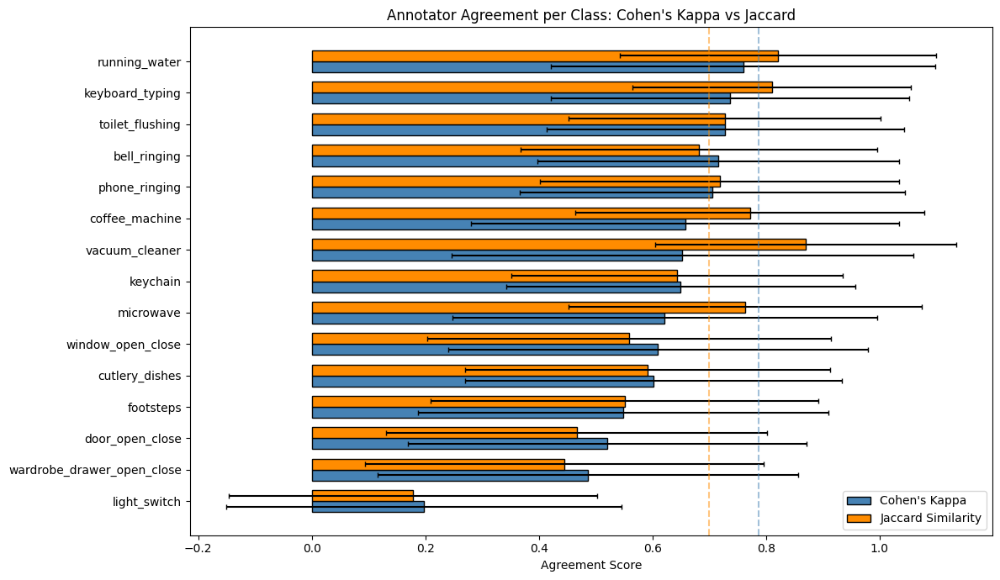

In [65]:
# ── Side-by-side bar chart: Kappa vs Jaccard ──
fig, ax = plt.subplots(figsize=(12, 7))

y_pos = np.arange(len(agreement_df))
bar_width = 0.35

ax.barh(y_pos - bar_width/2, agreement_df["mean_kappa"],
        bar_width, xerr=agreement_df["std_kappa"],
        label="Cohen's Kappa", color="steelblue", edgecolor="black", capsize=2)
ax.barh(y_pos + bar_width/2, agreement_df["mean_jaccard"],
        bar_width, xerr=agreement_df["std_jaccard"],
        label="Jaccard Similarity", color="darkorange", edgecolor="black", capsize=2)

ax.set_yticks(y_pos)
ax.set_yticklabels(agreement_df["class"])
ax.set_xlabel("Agreement Score")
ax.set_title("Annotator Agreement per Class: Cohen's Kappa vs Jaccard")
ax.legend(loc="lower right")
ax.axvline(x=np.mean(overall_kappas), color="steelblue", linestyle="--", alpha=0.5)
ax.axvline(x=np.mean(overall_jaccards), color="darkorange", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("agreement_kappa_vs_jaccard.png", dpi=150)
plt.show()

### (a) Do temporal annotations agree with uploader's target class tags?

In [66]:
# ── Compare temporal annotations vs. uploader target_classes metadata ──
# For each file: which classes appear in the annotation (any annotator, any time step > 0.5)?
# vs. which classes are listed in target_classes?

agreement_with_tags = {"file_id": [], "target_in_ann": [], "ann_not_in_target": [],
                       "target_not_in_ann": [], "n_target": [], "n_annotated": []}

for rec in records:
    ann = rec["annotations"]
    class_names = rec["class_names"]
    ann_max = ann.max(axis=(0, 2))
    annotated_classes = set(c for c, v in zip(class_names, ann_max) if v > BINARIZE_THRESH)
    target_set = set(rec["target_classes"])
    overlap = annotated_classes & target_set

    agreement_with_tags["file_id"].append(rec["file_id"])
    agreement_with_tags["target_in_ann"].append(len(overlap))
    agreement_with_tags["ann_not_in_target"].append(len(annotated_classes - target_set))
    agreement_with_tags["target_not_in_ann"].append(len(target_set - annotated_classes))
    agreement_with_tags["n_target"].append(len(target_set))
    agreement_with_tags["n_annotated"].append(len(annotated_classes))

tag_df = pd.DataFrame(agreement_with_tags)
tag_df["overlap_ratio"] = tag_df["target_in_ann"] / (
    tag_df["n_target"] + tag_df["n_annotated"] - tag_df["target_in_ann"]
).clip(lower=1)

print(f"Mean overlap ratio: {tag_df['overlap_ratio'].mean():.4f}")
print(f"Files where ALL targets found: {(tag_df['target_not_in_ann'] == 0).sum()} / {len(tag_df)}")
print(f"Files with extra classes:      {(tag_df['ann_not_in_target'] > 0).sum()} / {len(tag_df)}")

Mean overlap ratio: 0.9003
Files where ALL targets found: 3131 / 3656
Files with extra classes:      608 / 3656


### (a) Own-recording annotators vs. others

In [67]:
# ── Compare agreement of annotators who recorded the audio vs. others ──
own_kappas = []
other_kappas = []

for rec in records:
    ann = rec["annotations"]  # [T, C, A]
    T, C, A = ann.shape
    is_own = rec["is_own_recording"]

    if A < 2:
        continue # skip if less than 2 annotators 

    ann_bin = (ann > BINARIZE_THRESH).astype(int)

    for i, j in combinations(range(A), 2):
        y_i_all = ann_bin[:, :, i].flatten()
        y_j_all = ann_bin[:, :, j].flatten()

        if len(np.unique(y_i_all)) <= 1 and len(np.unique(y_j_all)) <= 1:
            kappa = 1.0 if np.array_equal(y_i_all, y_j_all) else 0.0
        else:
            kappa = cohen_kappa_score(y_i_all, y_j_all)

        # If at least one of the pair is the recording owner
        if is_own[i] or is_own[j]:
            own_kappas.append(kappa)
        else:
            other_kappas.append(kappa)

print(f"Pairs involving own-recording annotator: "
      f"mean kappa = {np.mean(own_kappas):.4f} (n={len(own_kappas)})")
if other_kappas:
    print(f"Pairs without own-recording annotator:  "
          f"mean kappa = {np.mean(other_kappas):.4f} (n={len(other_kappas)})")
else:
    print("All pairs include the own-recording annotator (only 2 annotators per file).")

Pairs involving own-recording annotator: mean kappa = 0.7921 (n=4170)
Pairs without own-recording annotator:  mean kappa = 0.7757 (n=1565)


Interpretation: kappa is higher when the recording owner is involved, that suggests the person who captured the audio provides more consistent/accurate annotations (they know what sounds were present)

/var/folders/tq/mn4dyv0d341767by7q6_x1680000gn/T/ipykernel_49579/2452698696.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", C)


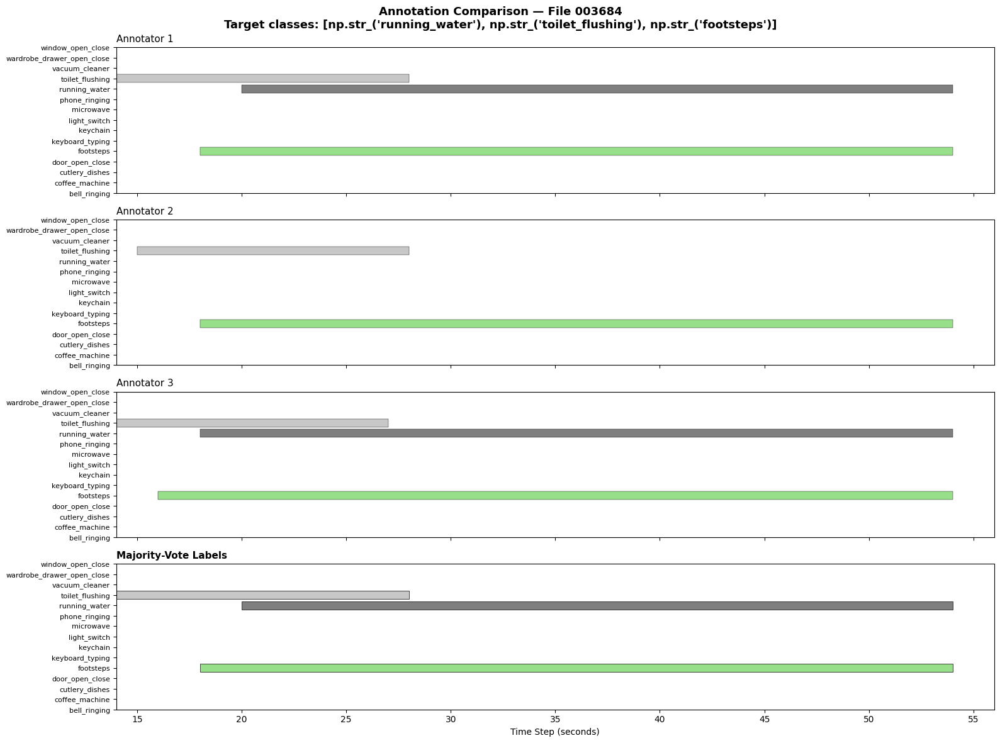

In [ ]:
# Case study: file 003684
# annotation comparison for a specific file ──
def plot_gantt_annotations(file_id, records, class_names):
    """Plot each annotator's binary annotations as horizontal bars."""
    rec = next(r for r in records if r["file_id"] == file_id)
    ann = rec["annotations"]  # [T, C, A]
    T, C, A = ann.shape
    ann_bin = (ann > BINARIZE_THRESH).astype(int)

    fig, axes = plt.subplots(A + 1, 1, figsize=(16, 3 * (A + 1)),
                             sharex=True, sharey=True)
    if A + 1 == 1:
        axes = [axes]

    time = np.arange(T)
    cmap = plt.cm.get_cmap("tab20", C)

    for a_idx in range(A):
        ax = axes[a_idx]
        is_own = rec["is_own_recording"][a_idx]
        owner_tag = " (owner)" if is_own else ""
        ax.set_title(f"Annotator {a_idx + 1}{owner_tag}", fontsize=11, loc="left")

        for c_idx in range(C):
            col = ann_bin[:, c_idx, a_idx]
            if col.sum() == 0:
                continue
            # Find contiguous runs
            padded = np.concatenate([[0], col, [0]])
            diffs = np.diff(padded)
            starts = np.where(diffs == 1)[0]
            ends = np.where(diffs == -1)[0]
            for s, e in zip(starts, ends):
                ax.barh(c_idx, e - s, left=s, height=0.8,
                        color=cmap(c_idx), edgecolor="black", linewidth=0.3)

        ax.set_yticks(range(C))
        ax.set_yticklabels(class_names, fontsize=8)
        ax.invert_yaxis()

    # Last subplot: majority-vote labels
    ax = axes[A]
    labels = rec["labels"]  # [T, C]
    ax.set_title("Majority-Vote Labels", fontsize=11, loc="left", fontweight="bold")
    for c_idx in range(C):
        col = labels[:, c_idx]
        if col.sum() == 0:
            continue
        padded = np.concatenate([[0], col, [0]])
        diffs = np.diff(padded)
        starts = np.where(diffs == 1)[0]
        ends = np.where(diffs == -1)[0]
        for s, e in zip(starts, ends):
            ax.barh(c_idx, e - s, left=s, height=0.8,
                    color=cmap(c_idx), edgecolor="black", linewidth=0.5)
    ax.set_yticks(range(C))
    ax.set_yticklabels(class_names, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Time Step (seconds)")

    fig.suptitle(f"Annotation Comparison — File {file_id}\n"
                 f"Target classes: {rec['target_classes']}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"gantt_annotations_{file_id}.png", dpi=150)
    plt.show()

plot_gantt_annotations("003684", records, CLASS_NAMES)

### (b) Convert Annotations to Labels: Aggregation & Binarization
##### This is the core label derivation. Strategy:

Binarize each annotator's soft annotation (> 0.5 → 1)
Majority vote across annotators (mean of binary annotations ≥ 0.5 → 1)

In [95]:
# ── 2b: Convert Annotations to Labels ──

def annotations_to_labels(annotations, binarize_thresh=0.5, vote_thresh=0.5):
    """
    Aggregate [T, C, A] annotations into binary labels [T, C].

    Step 1: Binarize each annotator (overlap > 0.5 → 1).
    Step 2: Average across annotators  (mean ≥ 0.5 → 1).
    """
    # Step 1: soft overlap → hard binary per annotator
    ann_bin = (annotations > binarize_thresh).astype(np.float32)  # [T, C, A]

    # Step 2: majority vote across annotators
    ann_mean = ann_bin.mean(axis=2)  # [T, C]
    labels = (ann_mean >= vote_thresh).astype(np.int8)  # [T, C]

    return labels


# ── Apply to all recordings ──
for rec in records:
    rec["labels"] = annotations_to_labels(rec["annotations"])
    
# Verification
sample = records[0]
print(f"File: {sample['file_id']}")
print(f"  Annotation shape: {sample['annotations'].shape}")
print(f"  Labels shape:     {sample['labels'].shape}")
print(f"  Target classes:   {sample['target_classes']}")
print(f"  Active classes:   "
      f"{[CLASS_NAMES[c] for c in range(NUM_CLASSES) if sample['labels'][:, c].any()]}")

File: 000001
  Annotation shape: (61, 15, 2)
  Labels shape:     (61, 15)
  Target classes:   [np.str_('keyboard_typing'), np.str_('phone_ringing')]
  Active classes:   ['keyboard_typing', 'phone_ringing']


In [58]:
records[0]

{'file_id': '000001',
 'annotations': array([[[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],
 
        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],
 
        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],
 
        ...,
 
        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],
 
        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]],
 
        [[0., 0.],
         [0., 0.],
         [0., 0.],
         ...,
         [0., 0.],
         [0., 0.],
         [0., 0.]]], shape=(61, 15, 2), dtype=float32),
 'class_names': ['bell_ringing',
  'coffee_machine',
  'cutlery_dishes',
  'door_open_close',
  'footsteps',
  'keyboard_typing'

In [96]:
# How many files have only 1 annotator 
# ── Files by annotator count ──
annotator_counts = [rec["annotations"].shape[2] for rec in records]
ann_count_series = pd.Series(annotator_counts)

print("Files by number of annotators:")
for n, cnt in sorted(ann_count_series.value_counts().items()):
    print(f"  {n} annotator(s): {cnt} files ({cnt/len(records)*100:.1f}%)")

n_single = (ann_count_series == 1).sum()
print(f"\nFiles with only 1 annotator: {n_single}")
print("→ These have NO majority vote possible; the single annotator's "
      "judgment becomes ground truth directly.")
print("→ They are kept for training data (more data) but excluded "
      "from agreement analysis (kappa requires ≥2 raters).")

# Check how many single-annotator files have is_own_recording = True
n_single_own = sum(
    1 for rec in records
    if rec["annotations"].shape[2] == 1 and rec["is_own_recording"][0]
)
print(f"  Of those, {n_single_own} are annotated by the recording owner.")

Files by number of annotators:
  1 annotator(s): 625 files (17.1%)
  2 annotator(s): 1750 files (47.9%)
  3 annotator(s): 1235 files (33.8%)
  4 annotator(s): 45 files (1.2%)
  5 annotator(s): 1 files (0.0%)

Files with only 1 annotator: 625
→ These have NO majority vote possible; the single annotator's judgment becomes ground truth directly.
→ They are kept for training data (more data) but excluded from agreement analysis (kappa requires ≥2 raters).
  Of those, 356 are annotated by the recording owner.


In [97]:
# silent segment analysis 
# ── Silent segments: how many time steps have no active class? ──
total_active = 0
total_silent = 0
total_multi = 0
total_steps = 0

for rec in records:
    labels = rec["labels"]
    n_active = labels.sum(axis=1)   # [T] — classes active per step
    total_steps += len(n_active)
    total_active += (n_active >= 1).sum()
    total_silent += (n_active == 0).sum()
    total_multi += (n_active >= 2).sum()

print(f"Total segments:     {total_steps}")
print(f"Active (≥1 class):  {total_active} ({total_active/total_steps*100:.1f}%)")
print(f"Silent (no class):  {total_silent} ({total_silent/total_steps*100:.1f}%)")
print(f"Multi-class (≥2):   {total_multi} ({total_multi/total_steps*100:.1f}%)")
print(f"\nSilent segments are labeled as all-zeros — this is correct.")
print("A classifier needs negative examples to learn when NO event is happening.")

Total segments:     168239
Active (≥1 class):  123993 (73.7%)
Silent (no class):  44246 (26.3%)
Multi-class (≥2):   28147 (16.7%)

Silent segments are labeled as all-zeros — this is correct.
A classifier needs negative examples to learn when NO event is happening.


### (c) Label Characteristics: Frequency & Duration

In [98]:
# ── 2c: Label Characteristics ──


# ── Class frequency: how many files contain each class, total active seconds ──
class_file_count = np.zeros(NUM_CLASSES, dtype=int)
class_total_seconds = np.zeros(NUM_CLASSES, dtype=float)
class_event_durations = {c: [] for c in CLASS_NAMES}  # list of event durations per class

total_seconds = 0.0

for rec in records:
    labels = rec["labels"]  # [T, C]
    T = labels.shape[0]
    total_seconds += T * TIME_STEP_SEC

    for c_idx in range(NUM_CLASSES):
        col = labels[:, c_idx]
        if col.any():
            class_file_count[c_idx] += 1
        class_total_seconds[c_idx] += col.sum() * TIME_STEP_SEC

        # ── Compute individual event durations (contiguous runs of 1s) ──
        # Pad with 0 to detect edges
        padded = np.concatenate([[0], col, [0]])
        diffs = np.diff(padded)
        starts = np.where(diffs == 1)[0]
        ends = np.where(diffs == -1)[0]
        durations = (ends - starts) * TIME_STEP_SEC
        class_event_durations[CLASS_NAMES[c_idx]].extend(durations.tolist())

# ── Summary table ──
char_df = pd.DataFrame({
    "class":         CLASS_NAMES,
    "n_files":       class_file_count,
    "total_sec":     class_total_seconds,
    "n_events":      [len(class_event_durations[c]) for c in CLASS_NAMES],
    "mean_dur_sec":  [np.mean(class_event_durations[c]) if class_event_durations[c] else 0
                      for c in CLASS_NAMES],
    "median_dur_sec":[np.median(class_event_durations[c]) if class_event_durations[c] else 0
                      for c in CLASS_NAMES],
    "pct_total_time":[s / total_seconds * 100 for s in class_total_seconds],
}).sort_values("n_files", ascending=False).reset_index(drop=True)

print(f"Total dataset duration: {total_seconds:.0f} seconds "
      f"({total_seconds/3600:.1f} hours)")
print()
print(char_df.to_string(index=False))

Total dataset duration: 168239 seconds (46.7 hours)

                     class  n_files  total_sec  n_events  mean_dur_sec  median_dur_sec  pct_total_time
                 footsteps     1815    25683.0      3063      8.384917             7.0       15.265783
           door_open_close     1155     8347.0      1988      4.198692             3.0        4.961394
             running_water      995    22834.0      1083     21.084026            17.0       13.572358
            cutlery_dishes      791    11976.0      1681      7.124331             4.0        7.118445
             phone_ringing      771    11926.0      1109     10.753832             7.0        7.088725
           keyboard_typing      725    16867.0      1051     16.048525            13.0       10.025618
                  keychain      675     9436.0      1227      7.690302             5.0        5.608688
wardrobe_drawer_open_close      592     4568.0      1184      3.858108             3.0        2.715185
         window_open

### (c) Visualization: Class frequency bar chart

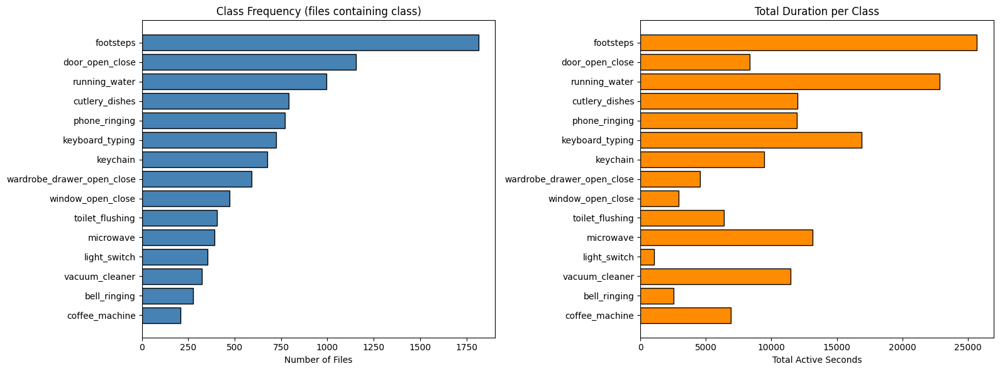

In [99]:
# ── Bar chart: number of files per class ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: file count
char_sorted = char_df.sort_values("n_files", ascending=True)
axes[0].barh(char_sorted["class"], char_sorted["n_files"], color="steelblue", edgecolor="black")
axes[0].set_xlabel("Number of Files")
axes[0].set_title("Class Frequency (files containing class)")

# Right: total active seconds
axes[1].barh(char_sorted["class"], char_sorted["total_sec"], color="darkorange", edgecolor="black")
axes[1].set_xlabel("Total Active Seconds")
axes[1].set_title("Total Duration per Class")

plt.tight_layout()
plt.savefig("label_frequency.png", dpi=150)
plt.show()

### (c) Event duration distribution

/var/folders/tq/mn4dyv0d341767by7q6_x1680000gn/T/ipykernel_49579/3482307392.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(dur_data, vert=False, labels=active_classes, patch_artist=True,


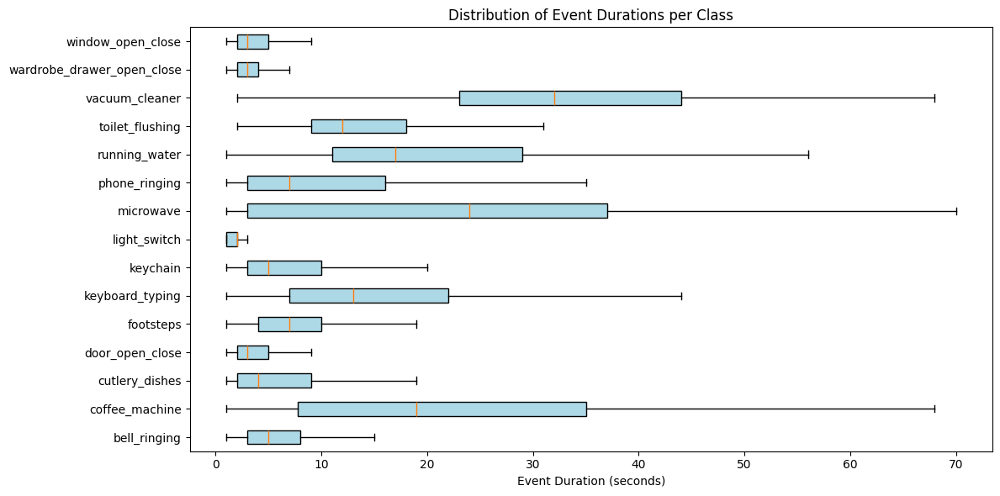

In [100]:
# ── Box plot of event durations per class ──
# Only include classes that have at least 1 event
active_classes = [c for c in CLASS_NAMES if len(class_event_durations[c]) > 0]
dur_data = [class_event_durations[c] for c in active_classes]

fig, ax = plt.subplots(figsize=(12, 6))
bp = ax.boxplot(dur_data, vert=False, labels=active_classes, patch_artist=True,
                showfliers=False)  # hide outliers for readability
for patch in bp["boxes"]:
    patch.set_facecolor("lightblue")
ax.set_xlabel("Event Duration (seconds)")
ax.set_title("Distribution of Event Durations per Class")
plt.tight_layout()
plt.savefig("event_durations.png", dpi=150)
plt.show()

### (c) Co-occurrence matrix

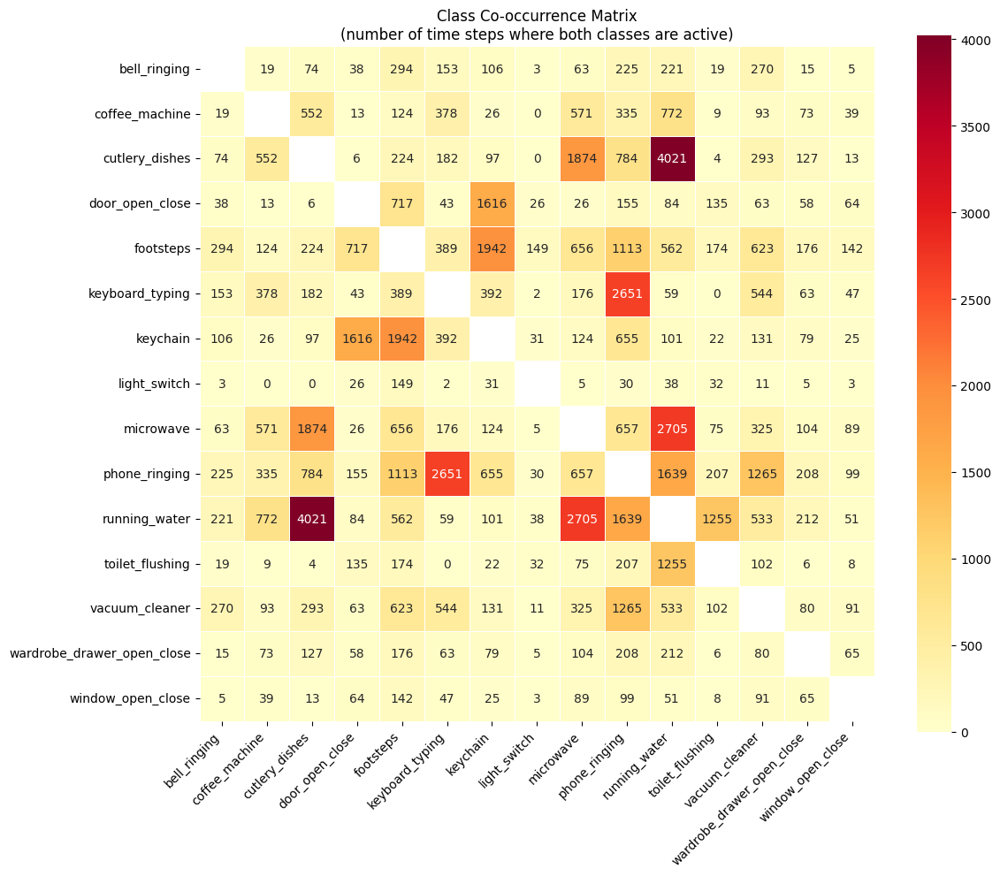

In [101]:
# ── Co-occurrence: how often two classes are active in the same time step ──
cooccurrence = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)

for rec in records:
    labels = rec["labels"]  # [T, C]
    # For each time step, find which classes are active
    cooccurrence += labels.T @ labels  # [C, C] — dot product counts co-active steps

# Normalize: the diagonal holds each class's total active steps
fig, ax = plt.subplots(figsize=(12, 10))
# Use raw counts for the heatmap
mask = np.zeros_like(cooccurrence, dtype=bool)
np.fill_diagonal(mask, True)  # mask diagonal (self-co-occurrence = just frequency)

sns.heatmap(cooccurrence, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            annot=True, fmt="d", cmap="YlOrRd", mask=mask, ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Class Co-occurrence Matrix\n(number of time steps where both classes are active)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("cooccurrence_matrix.png", dpi=150)
plt.show()


## 2- Annotations 
## 2(a) Annotator Agreement

**Method:** We quantified annotator agreement using Cohen's Kappa, a standard metric that accounts for chance agreement. For each recording with at least two annotators, we binarized the soft annotation values (threshold > 0.5 means the sound event is present in that 1-second segment), then computed pairwise Cohen's Kappa — both per-class and across all classes combined. This was done over 5,735 annotator pairs across 3,656 recordings.

**Overall agreement:** The overall mean Cohen's Kappa is **0.7876** (std: 0.201), which falls in the **substantial agreement** range on the Landis & Koch scale (0.61–0.80). This indicates that annotators generally agree well on which sound events are present and when they occur.
##### Explaination  

**Class-wise agreement:** Agreement varies noticeably across classes. The highest-agreement classes are **running_water** (κ=0.760), **keyboead_typing** (κ=0.737), and **toilet_flushing** (κ=0.728) — explained by their unique acoutstic sound and isolated environment that usually do not involve other simultaneous   events. The lowest-agreement classes are **light_switch** (κ=0.197515), **wardrobe_drawer_open_close** (κ=0.486626), and **door_open_close** (κ=0.520247)
This makes intuitive sense: these least agreed events are mostly short and can be confused with other impact sounds as they can be easly overlaped with similar transient events. The footsteps is the fourth disagreed class is its long and repetitive activity that might incure disagreement on the onset/ offset thresholds. 


                     class  mean_kappa  std_kappa  median_kappa  n_pairs
              light_switch    0.197515   0.348178      0.000000      730
wardrobe_drawer_open_close    0.486626   0.370756      0.538773      962
           door_open_close    0.520247   0.351413      0.600578     1926
                 footsteps    0.548912   0.361242      0.663583     2950
            cutlery_dishes    0.602603   0.331825      0.693878     1289
         window_open_close    0.609864   0.369339      0.730464      800
                 microwave    0.621662   0.374361      0.763578      627
                  keychain    0.649503   0.307453      0.732772     1072
            vacuum_cleaner    0.652781   0.406239      0.881943      528
            coffee_machine    0.658066   0.376892      0.840186      316
             phone_ringing    0.705576   0.338679      0.840052     1213
              bell_ringing    0.716530   0.318598      0.841629      429
           toilet_flushing    0.728158   0.314931      0.866142      667
           keyboard_typing    0.736751   0.314997      0.874608     1177
             running_water    0.759881   0.338978      0.922799     1579


**Temporal annotations vs. uploader target tags:** The mean overlap ratio between annotated classes and the uploader's declared target classes in the metadata is **0.90**. In 3131 out of 3656 files (85.6%), all target classes specified by the uploader were indeed found in the temporal annotations. In 608 files (16.6%), annotators identified additional classes beyond the uploader's targets — which is expected, since uploaders only list the *intended* target sounds, while annotators may detect incidental background events (e.g., footsteps during a coffee machine recording, keychain during door_open_close). Overall, the temporal annotations align well with the uploader metadata.

Mean overlap ratio (annotations vs. target tags): 0.9003
Files where ALL target classes appear in annotations: 3131 / 3656
Files with extra annotated classes beyond targets: 608 / 3656

Mean target classes per file: 2.79
Mean annotated classes per file: 2.83
____


**Own-recording annotators:** Pairs involving the person who captured the recording show slightly higher agreement (κ=0.792, n=4,170) compared to pairs where neither annotator is the recorder (κ=0.776, n=1,565). The difference is small  but consistent with the expectation that the recording collector has first hand knowledge of which sounds were present and when, giving them a slight advantage in annotation accuracy.

Pairs involving own-recording annotator: mean kappa = 0.7921 (n=4170)
Pairs without own-recording annotator:  mean kappa = 0.7757 (n=1565)
---

## 2(b) Convert Annotations to Labels


**Method:** We convert the raw annotations [T, C, A] into binary labels [T, C] in three steps:

1. Binarize per annotator: For each annotator, we mark a sound event as present (1) if its overlap with the time segment exceeds 0.5, and absent (0) otherwise.
2. Majority vote: We average these binary decisions across all annotators. If at least half of them agree the event is present (average ≥ 0.5), the final label is 1; otherwise it is 0.

**Assumptions:**
- All annotators are treated equally. 
- A 0.5 overlap threshold is appropriate for deciding presence/absence at the segment level.
- Majority vote is a reasonable consensus strategy.

**When labels could be incorrect:**
- If all annotators make the same mistake (confusing two similar classes), majority vote preserves the error.
- With only 2 annotators (e.g [T, 15, 2]), any disagreement means one annotator "wins" — a tie at 0.5 is resolved as positive, which introduces a slight bias toward labeling events as present.
- Partial overlaps near the 0.5 boundary are sensitive to the exact threshold; a sound event that covers 49% of a segment is labeled absent while 51% is labeled present.
---

## 2(c) Label Characteristics

**Dataset scale:** The full dataset spans **168,239 seconds (~46.7 hours)** across 3,656 recordings.

**Class frequency:** The most common class is **footsteps**, appearing in 1,815 files (49.6% of all recordings) and accounting for 15.3% of total active time. Other very common classes include **door_open_close** (1,155 files), **running_water** (995 files), and **cutlery_dishes** (791 files). The rarest classes are **coffee_machine** (207 files), **bell_ringing** (276 files), and **vacuum_cleaner** (325 files). There is a clear class imbalance — footsteps are nearly 9× more frequent than coffee_machine in terms of file count.


**Event durations:** Classes fall into distinct temporal profiles. Sustained/continuous sounds have long average durations: **vacuum_cleaner** (mean 33.7s, median 32s), **microwave** (mean 23.2s, median 24s), **coffee_machine** (mean 22.7s, median 19s), and **running_water** (mean 21.1s, median 17s). These are appliances that run for extended periods. In contrast, transient/impulsive sounds have short durations: **light_switch** (mean 2.4s, median 2s), **wardrobe_drawer_open_close** (mean 3.9s, median 3s), and **door_open_close** (mean 4.2s, median 3s). **Footsteps** have an intermediate profile (mean 8.4s, median 7s), reflecting walking sequences of variable length.

**Co-occurrences:** The co-occurrence matrix reveals which classes tend to appear simultaneously. 


Common co-occurrences are cutlery_dishes with running_water, footsteps with door_open_close, and keyboard_typing with phone_ringing. Footsteps co-occur frequently with many other classes because walking naturally accompanies most domestic activities.

**Summary:** The dataset exhibits significant class imbalance both in file frequency and total duration. Event durations range from ~2 seconds (light_switch) to ~34 seconds (vacuum_cleaner), reflecting the physical nature of each sound source.

# 3- Audio feature 

### (a) Metadata: Load & inspect recording properties

In [103]:
# ── 3a: Metadata distributions ──
meta_df = pd.read_csv(DATASET_DIR / "metadata.csv")

print(f"Metadata shape: {meta_df.shape}")
print(f"Columns: {list(meta_df.columns)}")
meta_df.head(3)

Metadata shape: (3656, 9)
Columns: ['filename', 'target_classes', 'recording_device', 'device_placement', 'recording_environment', 'scene_description', 'license', 'collector_id', 'non_target_classes']


,filename,target_classes,recording_device,device_placement,recording_environment,scene_description,license,collector_id,non_target_classes
0,003075.wav,keyboard_typing;keychain,IPhone Xr,static,office,I was working on my laptop and playing with ke...,CC0 (Public Domain Dedication),04d6c4738cd1814c,fan_working;hand_moving_on_table
1,001117.wav,footsteps,Iphone 15 Pro,mobile,office,"I was walking and recorded a bird singing, car...",CC0 (Public Domain Dedication),f125c6e647565367,bird_sing;car
2,001982.wav,footsteps;door_open_close;cutlery_dishes,Surface Pro 8,static,living_room,I went to the patio door and opened it. I went...,CC0 (Public Domain Dedication),23f33a22e31d3072,NaN


### (a) Device placement distribution

Device Placement:
  static: 1970 (53.9%)
  mobile: 1686 (46.1%)


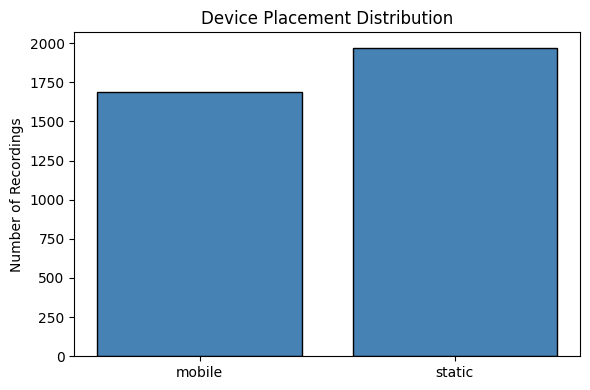

In [104]:
# ── Device placement ──
# Collect from npz
# ── Device placement ──
placements = []
devices = []
environments = []

for rec in records:
    data = dict(np.load(FEATURES_DIR / f"{rec['file_id']}.npz", allow_pickle=True))
    placements.append(str(data["device_placement"]))
    devices.append(str(data["recording_device"]))
    env = data["recording_environments"]
    if hasattr(env, '__iter__') and not isinstance(env, str):
        for e in env:
            environments.append((rec["file_id"], str(e).strip().lower()))
    else:
        environments.append((rec["file_id"], str(env).strip().lower()))

# Placement
placement_counts = Counter(placements)
print("Device Placement:")
for k, v in placement_counts.most_common():
    print(f"  {k}: {v} ({v/len(records)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(placement_counts.keys(), placement_counts.values(), color="steelblue", edgecolor="black")
ax.set_ylabel("Number of Recordings")
ax.set_title("Device Placement Distribution")
plt.tight_layout()
plt.savefig("placement_distribution.png", dpi=150)
plt.show()

### (a) Recording device distribution

Unique devices: 370


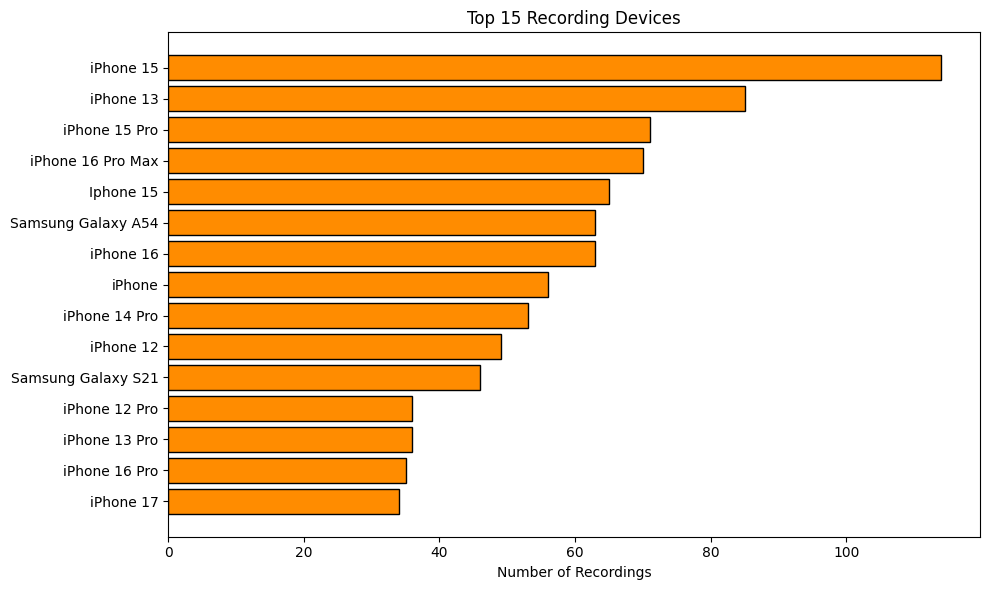

In [105]:
# ── Recording device distribution ──
# ── Recording devices (top 15) ──
device_counts = Counter(devices)
top_devices = device_counts.most_common(15)
print(f"Unique devices: {len(device_counts)}")
fig, ax = plt.subplots(figsize=(10, 6))
names, counts = zip(*top_devices)
ax.barh(names, counts, color="darkorange", edgecolor="black")
ax.set_xlabel("Number of Recordings")
ax.set_title("Top 15 Recording Devices")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("device_distribution.png", dpi=150)
plt.show()

### (a) Recording environment distribution

Unique environments: 55


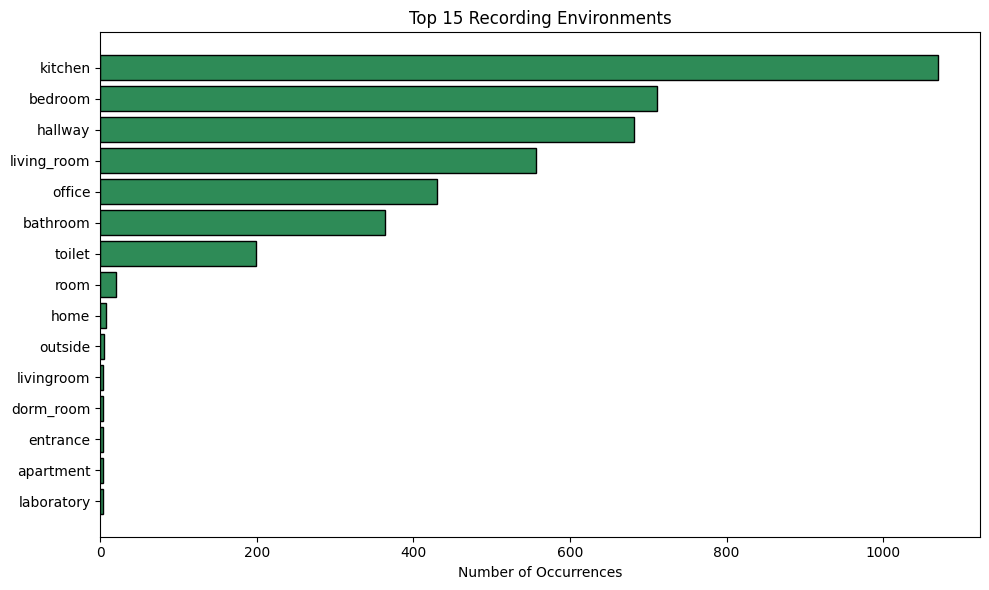

Unique recording environments: 55

Top 15 environments:
  kitchen: 1070
  bedroom: 711
  hallway: 682
  living_room: 557
  office: 430
  bathroom: 364
  toilet: 199
  room: 20
  home: 8
  outside: 5
  livingroom: 4
  dorm_room: 3
  entrance: 3
  apartment: 3
  laboratory: 3


In [107]:
# ── Recording environment distribution ──
# ── Recording environments (top 15) ──
env_only = [e[1] for e in environments]
env_counts = Counter(env_only)
top_envs = env_counts.most_common(15)
print(f"Unique environments: {len(env_counts)}")
fig, ax = plt.subplots(figsize=(10, 6))
names, counts = zip(*top_envs)
ax.barh(names, counts, color="seagreen", edgecolor="black")
ax.set_xlabel("Number of Occurrences")
ax.set_title("Top 15 Recording Environments")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("environment_distribution.png", dpi=150)
plt.show()

print(f"Unique recording environments: {len(env_counts)}")
print("\nTop 15 environments:")
for k, v in top_envs:
    print(f"  {k}: {v}")



In [108]:
# ── Most frequent class per recording environment ──
# Map file_id → list of active classes (from labels)
file_active_classes = {}
for rec in records:
    labels = rec["labels"]
    active = [CLASS_NAMES[c] for c in range(NUM_CLASSES) if labels[:, c].any()]
    file_active_classes[rec["file_id"]] = active

# Build environment → class counter
env_class_counter = {}
for file_id, env_name in environments:
    if env_name not in env_class_counter:
        env_class_counter[env_name] = Counter()
    for cls in file_active_classes.get(file_id, []):
        env_class_counter[env_name][cls] += 1

# Show top event per environment (top 15 environments)
top_env_names = [name for name, _ in env_counts.most_common(15)]
env_event_rows = []
for env_name in top_env_names:
    counter = env_class_counter.get(env_name, Counter())
    top3 = counter.most_common(3)
    env_event_rows.append({
        "environment": env_name,
        "n_recordings": env_counts[env_name],
        "top_1_class": top3[0][0] if len(top3) > 0 else "-",
        "top_1_count": top3[0][1] if len(top3) > 0 else 0,
        "top_2_class": top3[1][0] if len(top3) > 1 else "-",
        "top_2_count": top3[1][1] if len(top3) > 1 else 0,
        "top_3_class": top3[2][0] if len(top3) > 2 else "-",
        "top_3_count": top3[2][1] if len(top3) > 2 else 0,
    })

env_event_df = pd.DataFrame(env_event_rows)
print("Most frequent sound events per recording environment:")
print(env_event_df.to_string(index=False))

Most frequent sound events per recording environment:
environment  n_recordings     top_1_class  top_1_count     top_2_class  top_2_count                top_3_class  top_3_count
    kitchen          1070  cutlery_dishes          665   running_water          532                  footsteps          370
    bedroom           711       footsteps          450 door_open_close          226 wardrobe_drawer_open_close          207
    hallway           682       footsteps          543 door_open_close          514                   keychain          353
living_room           557       footsteps          347 door_open_close          185              phone_ringing          145
     office           430 keyboard_typing          348   phone_ringing          200                  footsteps          137
   bathroom           364   running_water          311 toilet_flushing          236                  footsteps          171
     toilet           199 toilet_flushing          175   running_water        

### (b) Feature Statistics: Define feature groups and collect all segments
load all feature arrays and stacks them into one large matrix.

In [109]:
# ── 3b: Feature Statistics ──

# Define the 14 base feature names and their dimensionalities
BBASE_FEATURES = {
    "zcr": 1, "melspect": 128, "mfcc": 32, "mfcc_d": 32, "mfcc_d2": 32,
    "flux": 1, "flatness": 1, "centroid": 1, "bandwidth": 1, "contrast": 7,
    "rolloff_low": 1, "rolloff_high": 1, "energy": 1, "power": 1,
}
AGGREGATIONS = ["mean", "std", "min", "max"]

# Build ordered list of all 960 feature key names
# e.g. "zcr_mean", "melspect_mean", ..., "power_max"
feature_keys = []
feature_group_labels = []   # which base feature each column belongs to
col_idx = 0      

for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        key = f"{base}_{agg}"
        feature_keys.append(key)
        for d in range(dim):
            feature_group_labels.append(base)
            col_idx += 1

print(f"Total feature columns: {col_idx}")  # 960

# ── Stack all segments into one big matrix [N_total, 960] ──
all_features = []

for rec in records:
    data = dict(np.load(FEATURES_DIR / f"{rec['file_id']}.npz", allow_pickle=True))
    T = data["annotations"].shape[0]
    row = []
    for key in feature_keys:
        feat = data[key]  # [T, D]
        if feat.ndim == 1:
            feat = feat.reshape(-1, 1)
        row.append(feat)
    all_features.append(np.concatenate(row, axis=1))  # [T, 960]

X_all = np.concatenate(all_features, axis=0)  # [N_total, 960]
print(f"Feature matrix shape: {X_all.shape}")

Total feature columns: 960
Feature matrix shape: (168239, 960)


### (b) Basic statistics per feature group

In [110]:
# ── Compute statistics per feature group (base feature name) ──
group_labels = np.array(feature_group_labels)  # length 960
unique_groups = list(BASE_FEATURES.keys())

stats_rows = []
for group in unique_groups:
    mask = group_labels == group
    X_group = X_all[:, mask]
    stats_rows.append({
        "feature_group": group, "n_dims": int(mask.sum()),
        "global_mean": float(np.mean(X_group)),
        "global_std": float(np.std(X_group)),
        "global_min": float(np.min(X_group)),
        "global_max": float(np.max(X_group)),
    })

stats_df = pd.DataFrame(stats_rows)
print(stats_df.to_string(index=False))

feature_group  n_dims  global_mean  global_std    global_min   global_max
          zcr       4     0.171481    0.167058  0.000000e+00     0.943359
     melspect     512     3.668569    2.666256  0.000000e+00    13.180177
         mfcc     128    -1.229553   12.381837 -1.302539e+02    44.912514
       mfcc_d     128     0.047058    0.468800 -1.543652e+01    17.211765
      mfcc_d2     128     0.026094    0.303257 -9.809211e+00     8.824092
         flux       4     3.194802    6.868446  0.000000e+00   166.599075
     flatness       4     0.096196    0.121835  2.420767e-08     1.000002
     centroid       4  1841.801357 1349.484574  0.000000e+00  7615.977622
    bandwidth       4  2149.686906 1265.242694  0.000000e+00  4951.661435
     contrast      28    13.825501   12.986936  0.000000e+00    80.107058
  rolloff_low       4   353.111197  540.029486  0.000000e+00  7437.500000
 rolloff_high       4  3900.309439 2470.888239  0.000000e+00  7937.500000
       energy       4    44.904031   9

### (b) Per-column statistics (compact summary)

In [111]:
# ── Per-column (per individual feature dimension) statistics ──
# Compact: show mean ± std across all segments for each of the 960 columns,
# then summarize by feature key (e.g., mfcc_mean has 32 dims → one summary row)

per_key_stats = []
col_idx = 0
for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        key = f"{base}_{agg}"
        cols = X_all[:, col_idx : col_idx + dim]
        per_key_stats.append({
            "key":       key,
            "dims":      dim,
            "mean":      f"{np.mean(cols):.4f}",
            "std":       f"{np.std(cols):.4f}",
            "min":       f"{np.min(cols):.4f}",
            "max":       f"{np.max(cols):.4f}",
        })
        col_idx += dim

per_key_df = pd.DataFrame(per_key_stats)
print(per_key_df.to_string(index=False))

              key  dims      mean       std       min        max
         zcr_mean     1    0.1914    0.1326    0.0000     0.8133
          zcr_std     1    0.0642    0.0428    0.0000     0.3827
          zcr_min     1    0.0815    0.0998    0.0000     0.7305
          zcr_max     1    0.3489    0.1754    0.0000     0.9434
    melspect_mean   128    4.5170    1.7801    0.0000    12.4547
     melspect_std   128    0.8534    0.4312    0.0000     5.2594
     melspect_min   128    2.6626    1.7120    0.0000    12.3593
     melspect_max   128    6.6414    1.9120    0.0000    13.1802
        mfcc_mean    32   -2.0445   14.2879 -130.2539    29.0836
         mfcc_std    32    1.0572    1.4527    0.0000    44.9125
         mfcc_min    32   -4.4926   15.7141 -130.2539    26.3286
         mfcc_max    32    0.5618   11.8450 -130.2539    39.2580
      mfcc_d_mean    32    0.0003    0.0301   -0.9224     1.1659
       mfcc_d_std    32    0.1590    0.1954    0.0000     5.4826
       mfcc_d_min    32  

### (b) Visualization: Box plots of scalar features

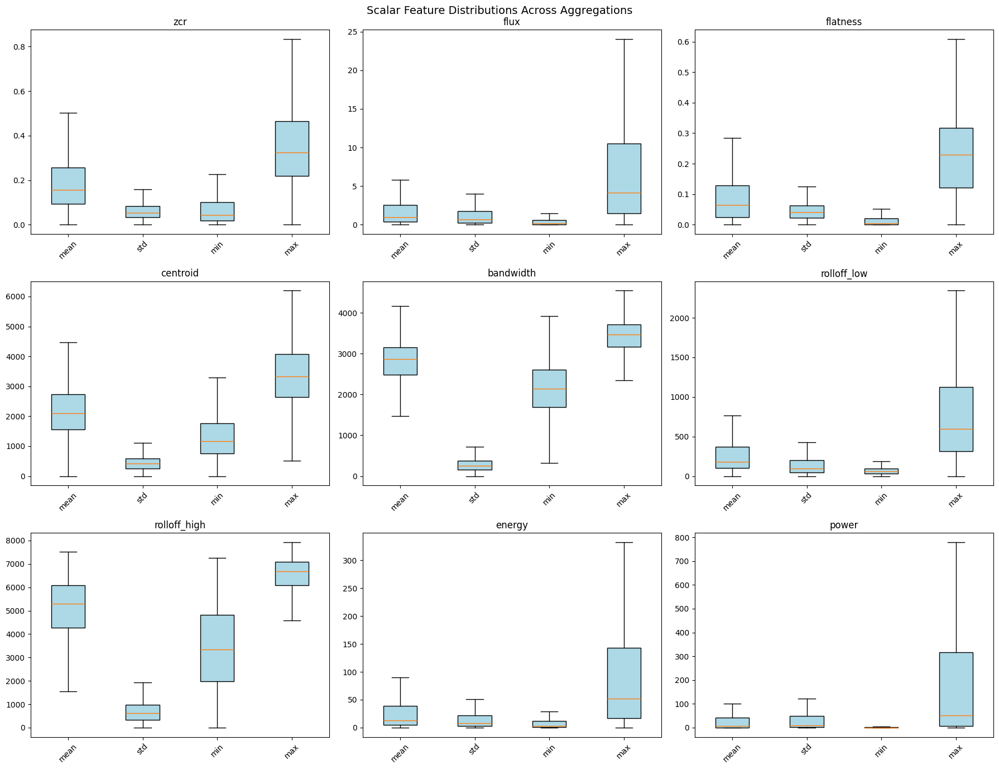

In [112]:
# ── Box plots for scalar features (dim=1) across aggregations ──
scalar_bases = [b for b, d in BASE_FEATURES.items() if d == 1] # Unidimensional features
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, base in enumerate(scalar_bases):
    ax = axes[idx]
    box_data = []
    box_labels = []
    col_cursor = 0
    for b, dim in BASE_FEATURES.items():
        for agg in AGGREGATIONS:
            if b == base:
                box_data.append(X_all[:, col_cursor].copy())
                box_labels.append(agg)
            col_cursor += dim

    # Subsample for speed (box plots with millions of points are slow)
    n_sub = min(50000, len(box_data[0]))
    rng = np.random.default_rng(42)
    sub_idx = rng.choice(len(box_data[0]), n_sub, replace=False)

    ax.boxplot([d[sub_idx] for d in box_data], tick_labels=box_labels,
               showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="lightblue"))
    ax.set_title(base)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle("Scalar Feature Distributions Across Aggregations", fontsize=14)
plt.tight_layout()
plt.savefig("scalar_feature_boxplots.png", dpi=150)
plt.show()

### (c) Feature Correlation: inter-group correlation

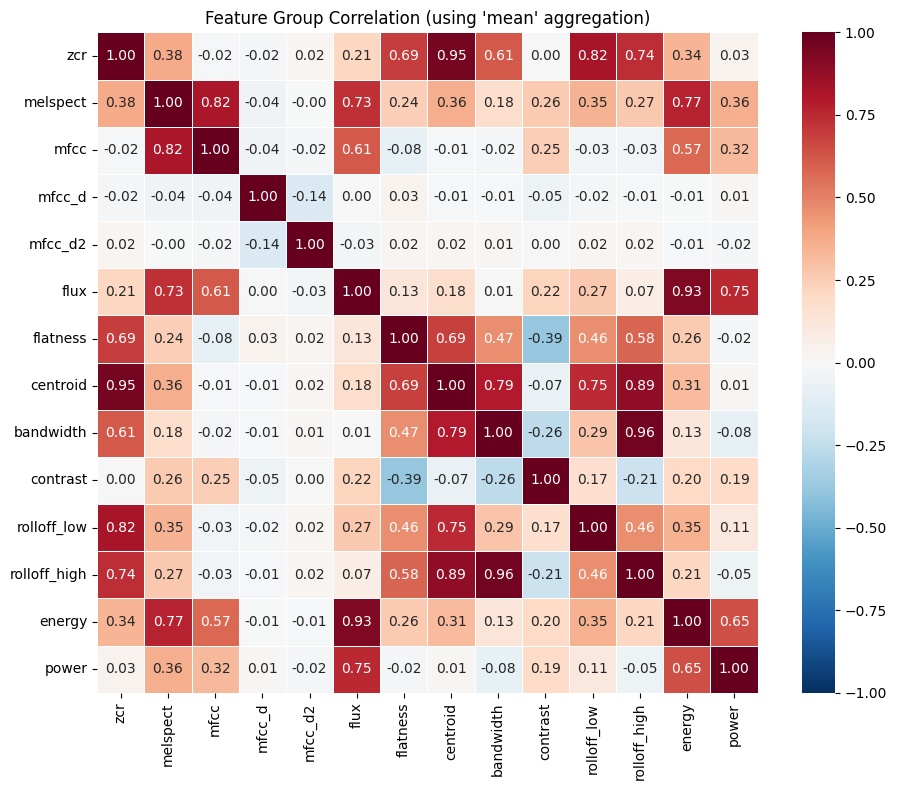

In [113]:
# ── 3c: Feature Correlation ──
# Computing the full 960×960 correlation matrix is expensive to visualize.
# Strategy: compute the MEAN value per feature group per segment,
# then compute correlation between these 14 group-level summaries.
# This shows which *categories* of features are correlated.

# For each aggregation method separately (use 'mean' aggregation as primary)
agg_to_use = "mean"

group_means = {}
col_idx = 0
for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        if agg == agg_to_use:
            cols = X_all[:, col_idx : col_idx + dim]
            group_means[base] = np.mean(cols, axis=1)  # [N_total,]
        col_idx += dim

group_df = pd.DataFrame(group_means)  # [N_total, 14]

# Correlation matrix between feature groups
corr_matrix = group_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5, ax=ax,
            vmin=-1, vmax=1)
ax.set_title(f"Feature Group Correlation (using '{agg_to_use}' aggregation)")
plt.tight_layout()
plt.savefig("feature_group_correlation.png", dpi=150)
plt.show()

### (c) Intra-group correlation: MFCC example

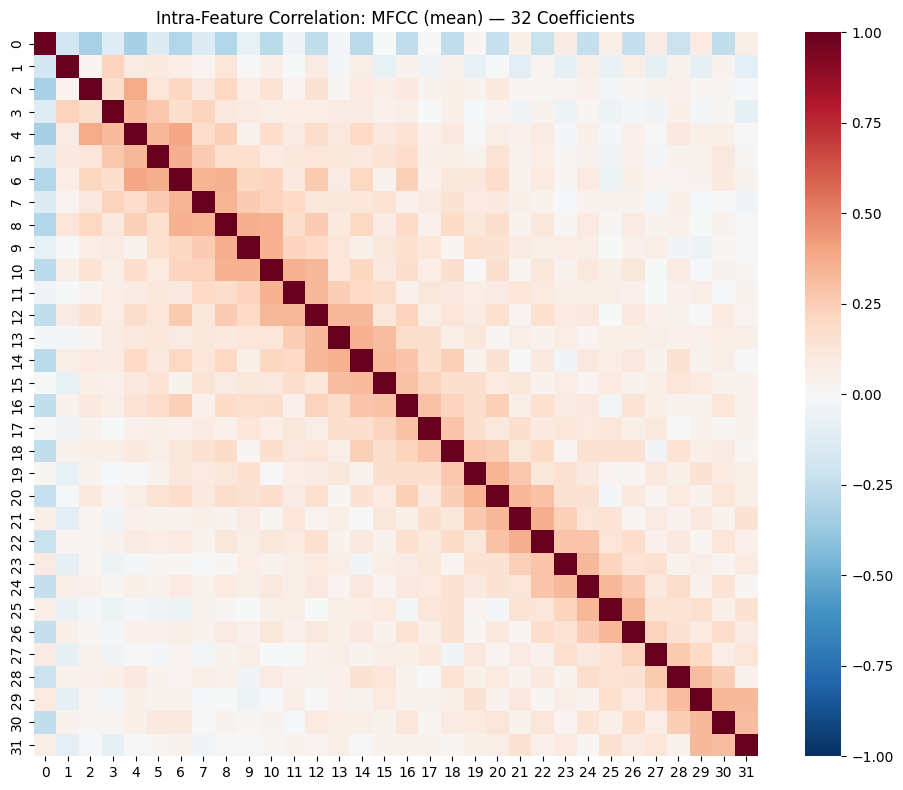

In [114]:
# ── Intra-group correlation example: MFCC coefficients (mean aggregation) ──
# Show how the 32 MFCC dimensions correlate with each other

col_idx = 0
mfcc_mean_cols = None
for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        if base == "mfcc" and agg == "mean":
            mfcc_mean_cols = X_all[:, col_idx : col_idx + dim]
        col_idx += dim

# mfcc_corr = np.corrcoef(mfcc_mean_cols.T)  # [32, 32]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(np.corrcoef(mfcc_mean_cols.T), cmap="RdBu_r", center=0, square=True,
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Intra-Feature Correlation: MFCC (mean) — 32 Coefficients")
plt.tight_layout()
plt.savefig("mfcc_intra_correlation.png", dpi=150)
plt.show()

### (c) Cross-aggregation correlation for a single feature

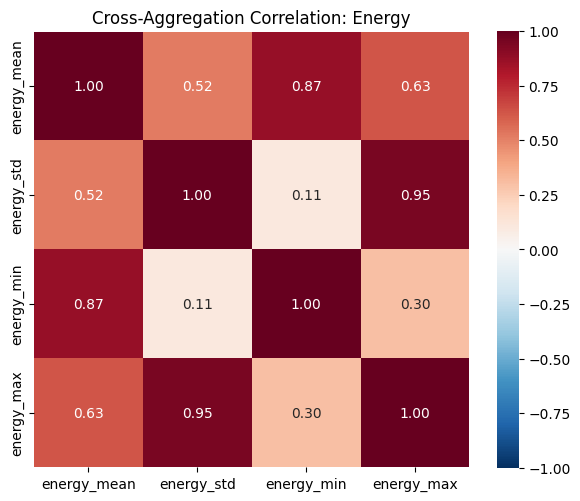

In [115]:
cross_agg_data = {}
col_idx = 0
for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        if base == "energy":
            cross_agg_data[f"energy_{agg}"] = X_all[:, col_idx]
        col_idx += dim

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(pd.DataFrame(cross_agg_data).corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, square=True, vmin=-1, vmax=1, ax=ax)
ax.set_title("Cross-Aggregation Correlation: Energy")
plt.tight_layout()
plt.savefig("energy_cross_agg_correlation.png", dpi=150)
plt.show()

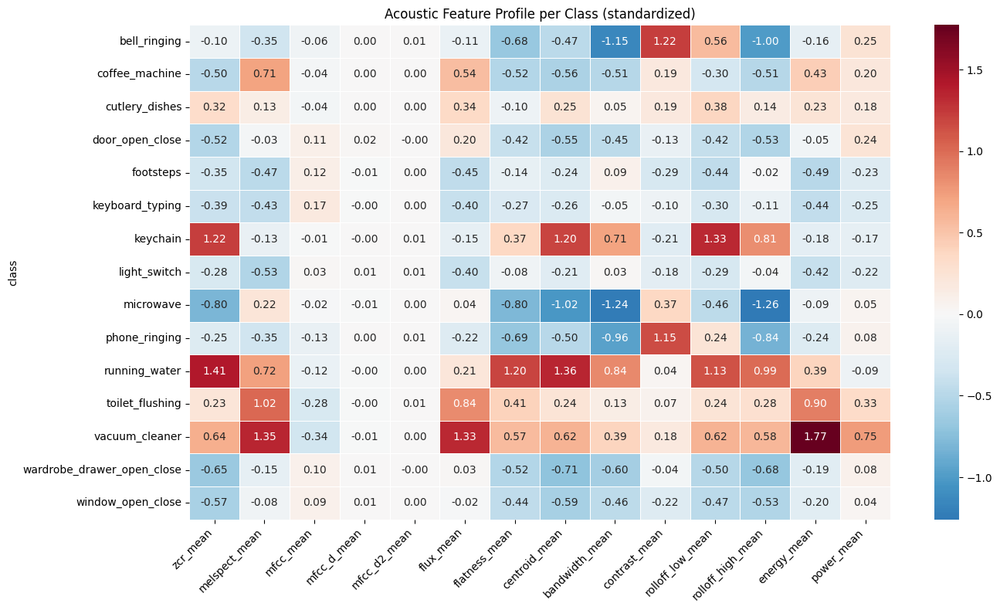

In [118]:
# ── Acoustic fingerprint per class ──
PROFILE_KEYS = [
    "zcr_mean", "melspect_mean", "mfcc_mean", "mfcc_d_mean", "mfcc_d2_mean",
    "flux_mean", "flatness_mean", "centroid_mean", "bandwidth_mean",
    "contrast_mean", "rolloff_low_mean", "rolloff_high_mean",
    "energy_mean", "power_mean",
]

profile_col_map = {}
col_idx = 0
for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        key = f"{base}_{agg}"
        if key in PROFILE_KEYS:
            profile_col_map[key] = list(range(col_idx, col_idx + dim))
        col_idx += dim

# Collect single-class segments per class
class_profiles = {cls: [] for cls in CLASS_NAMES}
for rec_idx, rec in enumerate(records):
    labels = rec["labels"]
    feats = all_features[rec_idx]
    for t in range(labels.shape[0]):
        active = np.where(labels[t] == 1)[0]
        if len(active) == 1:
            class_profiles[CLASS_NAMES[active[0]]].append(feats[t])

# Compute mean standardized value per class per feature
profile_results = {}
for cls in CLASS_NAMES:
    if not class_profiles[cls]:
        continue
    X_cls_norm = scaler_global.transform(np.array(class_profiles[cls]))
    row = {}
    for key, cols in profile_col_map.items():
        row[key] = np.mean(X_cls_norm[:, cols])
    profile_results[cls] = row

profile_df = pd.DataFrame(profile_results).T
profile_df.index.name = "class"

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(profile_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, ax=ax)
ax.set_title("Acoustic Feature Profile per Class (standardized)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("class_feature_profiles.png", dpi=150)
plt.show()

/var/folders/tq/mn4dyv0d341767by7q6_x1680000gn/T/ipykernel_49579/4136333469.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_r = plt.cm.get_cmap("tab10", len(COMPARE_CLASSES))


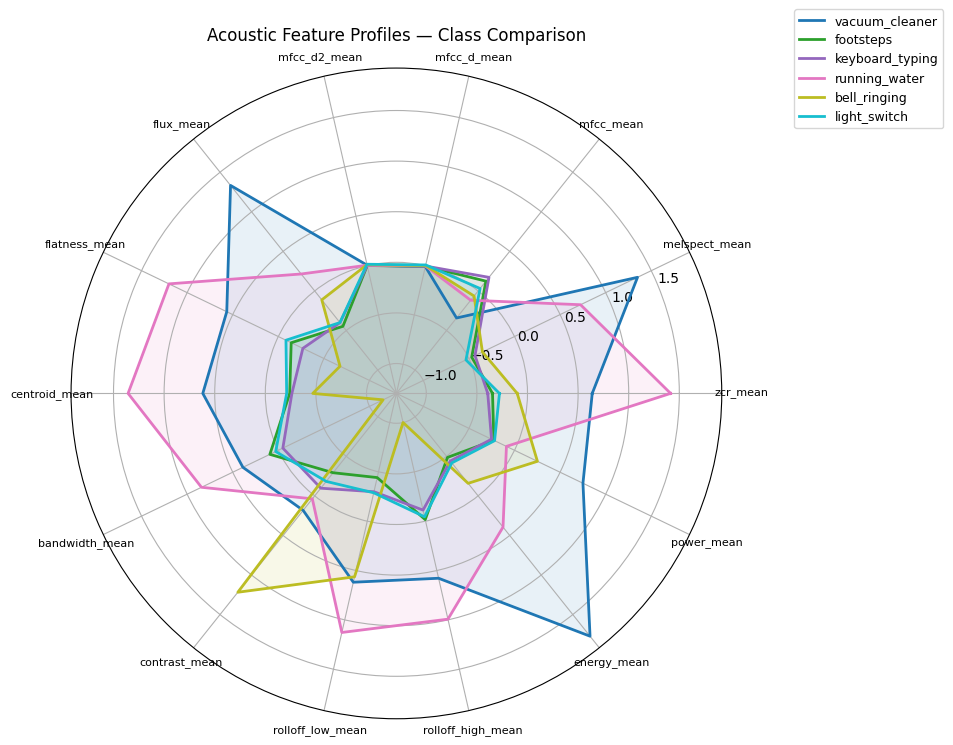

In [119]:
# ── Radar (spider) plot for selected classes ──
from matplotlib.patches import FancyBboxPatch

COMPARE_CLASSES = ["vacuum_cleaner", "footsteps", "keyboard_typing",
                   "running_water", "bell_ringing", "light_switch"]

features_radar = list(profile_df.columns)
N_feat = len(features_radar)
angles = np.linspace(0, 2 * np.pi, N_feat, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
cmap_r = plt.cm.get_cmap("tab10", len(COMPARE_CLASSES))

for idx, cls in enumerate(COMPARE_CLASSES):
    values = profile_df.loc[cls].values.tolist() + [profile_df.loc[cls].values[0]]
    ax.plot(angles, values, linewidth=2, label=cls, color=cmap_r(idx))
    ax.fill(angles, values, alpha=0.1, color=cmap_r(idx))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(features_radar, fontsize=8)
ax.set_title("Acoustic Feature Profiles — Class Comparison", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout()
plt.savefig("class_radar_profiles.png", dpi=150)
plt.show()

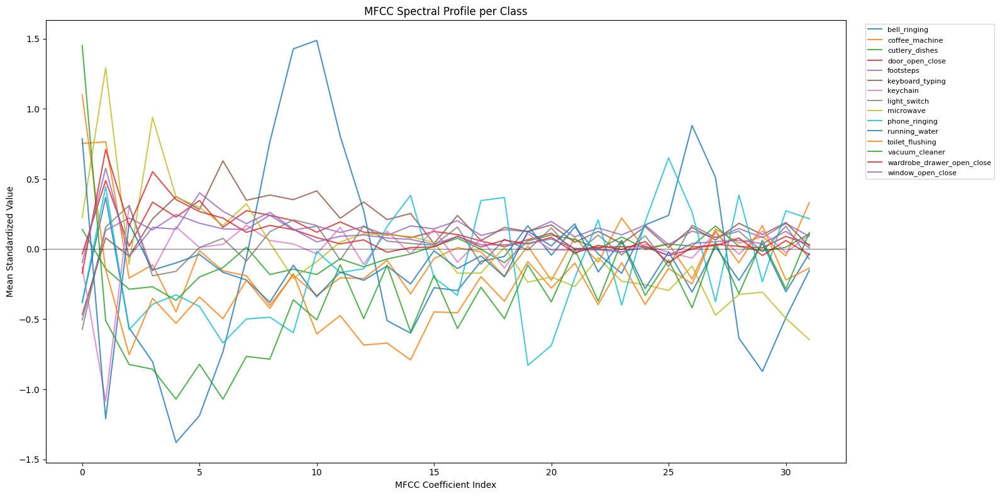

In [120]:
# ── MFCC coefficient profile per class ──
# Shows how the 32 MFCC coefficients differ across classes.
# This is the most detailed "spectral shape" comparison.

col_idx = 0
mfcc_cols = None
for base, dim in BASE_FEATURES.items():
    for agg in AGGREGATIONS:
        if base == "mfcc" and agg == "mean":
            mfcc_cols = list(range(col_idx, col_idx + dim))
        col_idx += dim

mfcc_profiles = {}
for cls in CLASS_NAMES:
    if class_profiles[cls]:
        X_cls_norm = scaler_global.transform(np.array(class_profiles[cls]))
        mfcc_profiles[cls] = np.mean(X_cls_norm[:, mfcc_cols], axis=0)

fig, ax = plt.subplots(figsize=(16, 8))
for cls in CLASS_NAMES:
    if cls in mfcc_profiles:
        ax.plot(range(32), mfcc_profiles[cls], label=cls, alpha=0.8, linewidth=1.5)
ax.set_xlabel("MFCC Coefficient Index")
ax.set_ylabel("Mean Standardized Value")
ax.set_title("MFCC Spectral Profile per Class")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.axhline(y=0, color="black", linestyle="-", alpha=0.3)
plt.tight_layout()
plt.savefig("mfcc_profiles_per_class.png", dpi=150)
plt.show()

### (d) Bonus: Prepare high-quality subset for visualization
Following the hint: select segments with high annotator agreement and only one class active.

In [151]:
# ── Feature selection for visualization ──
# Define which base features and aggregations to include.
# Modify these two dictionaries to experiment.

# OPTION 1: All features (current default) — 960 dims
SELECTED_FEATURES_ALL = {
    "zcr": 1, "melspect": 128, "mfcc": 32, "mfcc_d": 32, "mfcc_d2": 32,
    "flux": 1, "flatness": 1, "centroid": 1, "bandwidth": 1, "contrast": 7,
    "rolloff_low": 1, "rolloff_high": 1, "energy": 1, "power": 1,
}
SELECTED_AGGS_ALL = ["mean", "std", "min", "max"]

# OPTION 2: MFCCs only (mean + std) — compact timbral representation — 128 dims
SELECTED_FEATURES_MFCC = {
    "mfcc": 32, "mfcc_d": 32,
}
SELECTED_AGGS_MFCC = ["mean", "std"]

# OPTION 3: Spectral features only — 536 dims
SELECTED_FEATURES_SPECTRAL = {
    "melspect": 128, "centroid": 1, "bandwidth": 1, "flatness": 1,
    "contrast": 7, "rolloff_low": 1, "rolloff_high": 1,
}
SELECTED_AGGS_SPECTRAL = ["mean", "std"]

# OPTION 4: Hand-picked "best of" — diverse, low redundancy — 152 dims
# Rationale: MFCCs for spectral shape, deltas for dynamics,
# energy for loudness, flatness for tonal/noisy distinction,
# zcr for percussive detection. Skip melspect (redundant with MFCCs),
# skip bandwidth/rolloff_high (redundant with centroid per correlation).
SELECTED_FEATURES_CURATED = {
    "mfcc": 32, "mfcc_d": 32, "mfcc_d2": 32,
    "zcr": 1, "flatness": 1, "energy": 1, "contrast": 7,
}
SELECTED_AGGS_CURATED = ["mean", "std"]

# ──────────────────────────────────────
# SET YOUR CHOICE HERE:
SELECTED_FEATURES = SELECTED_FEATURES_SPECTRAL
SELECTED_AGGS = SELECTED_AGGS_SPECTRAL

# ──────────────────────────────────────

# Build column mask to extract selected features from the 960-column matrix
selected_col_indices = []
selected_col_names = []
col_idx = 0

for base, dim in BASE_FEATURES.items():           # iterates all 14 base features
    for agg in AGGREGATIONS:                        # iterates mean, std, min, max
        if base in SELECTED_FEATURES and agg in SELECTED_AGGS:
            # Include these columns
            for d in range(dim):
                selected_col_indices.append(col_idx + d)
                suffix = f"_{d}" if dim > 1 else ""
                selected_col_names.append(f"{base}_{agg}{suffix}")
        col_idx += dim

selected_col_indices = np.array(selected_col_indices)
print(f"Selected {len(selected_col_indices)} features out of 960:")
print(f"  Base features: {list(SELECTED_FEATURES.keys())}")
print(f"  Aggregations:  {SELECTED_AGGS}")
print(f"  Example columns: {selected_col_names[:10]} ...")

Selected 280 features out of 960:
  Base features: ['melspect', 'centroid', 'bandwidth', 'flatness', 'contrast', 'rolloff_low', 'rolloff_high']
  Aggregations:  ['mean', 'std']
  Example columns: ['melspect_mean_0', 'melspect_mean_1', 'melspect_mean_2', 'melspect_mean_3', 'melspect_mean_4', 'melspect_mean_5', 'melspect_mean_6', 'melspect_mean_7', 'melspect_mean_8', 'melspect_mean_9'] ...


## Record: 

SELECTED_FEATURES = SELECTED_FEATURES_CURATED;
SELECTED_AGGS = SELECTED_AGGS_CURATED

Selected 212 features out of 960:
  Base features: ['mfcc', 'mfcc_d', 'mfcc_d2', 'zcr', 'flatness', 'energy', 'contrast']
  Aggregations:  ['mean', 'std']

High-quality segments: 76716, dims: 212

Subsample: 14994 segments
PCA: 50 components capture 62.5% of variance 
Final KL divergence: 3.3826
Components for 90% variance: 123
Components for 95% variance: 148
Components for 99% variance: 190

______________________________________________________
======================================================
SELECTED_FEATURES = SELECTED_FEATURES_ALL;
SELECTED_AGGS = SELECTED_AGGS_ALL

Selected 960 features out of 960:
  Base features: ['zcr', 'melspect', 'mfcc', 'mfcc_d', 'mfcc_d2', 'flux', 'flatness', 'centroid', 'bandwidth', 'contrast', 'rolloff_low', 'rolloff_high', 'energy', 'power']
  Aggregations:  ['mean', 'std', 'min', 'max']

High-quality segments: 76716, dims: 960

Subsample: 14994 segments
PCA: 50 components capture 77.7% of variance
t-SNE complete. Final KL divergence: 2.2743

Components for 90% variance: 143
Components for 95% variance: 238
Components for 99% variance: 463

______________________________________________________
======================================================
SELECTED_FEATURES = SELECTED_FEATURES_MFCC
SELECTED_AGGS = SELECTED_AGGS_MFCC

Selected 128 features out of 960:
  Base features: ['mfcc', 'mfcc_d']
  Aggregations:  ['mean', 'std']

High-quality segments: 76716, dims: 128

Subsample: 14994 segments
PCA: 50 components capture 75.5% of variance
t-SNE complete. Final KL divergence: 3.3875

Components for 90% variance: 80
Components for 95% variance: 93
Components for 99% variance: 116

______________________________________________________
======================================================
SELECTED_FEATURES = SELECTED_FEATURES_SPECTRAL
SELECTED_AGGS = SELECTED_AGGS_SPECTRAL

Selected 280 features out of 960:
  Base features: ['melspect', 'centroid', 'bandwidth', 'flatness', 'contrast', 'rolloff_low', 'rolloff_high']
  Aggregations:  ['mean', 'std']

High-quality segments: 76716, dims: 280

Subsample: 14994 segments
PCA: 50 components capture 97.8% of variance
t-SNE complete. Final KL divergence: 1.9889

Components for 90% variance: 9
Components for 95% variance: 24
Components for 99% variance: 84

______________________________________________________
======================================================


In [152]:
# ── Build visualization subset using SELECTED features only ──
segment_features = []
segment_labels = []
AGREEMENT_THRESH = 0.8

for rec_idx, rec in enumerate(records):
    labels = rec["labels"]
    ann = rec["annotations"]
    T, C, A = ann.shape
    feats = all_features[rec_idx]  # [T, 960]
    ann_bin = (ann > BINARIZE_THRESH).astype(float)

    for t in range(T):
        active = np.where(labels[t] == 1)[0]
        if len(active) != 1:
            continue

        c_idx = active[0]
        agreement = ann_bin[t, c_idx, :].mean()
        if agreement < AGREEMENT_THRESH:
            continue

        # ── KEY CHANGE: only take selected columns ──
        segment_features.append(feats[t, selected_col_indices])
        segment_labels.append(CLASS_NAMES[c_idx])

X_vis = np.array(segment_features)
y_vis = np.array(segment_labels)

print(f"High-quality segments: {X_vis.shape[0]}, dims: {X_vis.shape[1]}")

High-quality segments: 76716, dims: 280


### (d) Bonus: PCA for initial dimensionality reduction + t-SNE

In [153]:
from sklearn.manifold import TSNE

# ── Stratified subsample (t-SNE is O(n²), cap at ~15k) ──
MAX_SAMPLES = 15000
rng = np.random.default_rng(42)

if X_vis.shape[0] > MAX_SAMPLES:
    sub_indices = []
    for cls in np.unique(y_vis):
        cls_idx = np.where(y_vis == cls)[0]
        n_take = max(50, int(MAX_SAMPLES * len(cls_idx) / len(y_vis)))
        n_take = min(n_take, len(cls_idx))
        sub_indices.extend(rng.choice(cls_idx, n_take, replace=False).tolist())
    sub_indices = np.array(sub_indices)
    X_sub = X_vis[sub_indices]
    y_sub = y_vis[sub_indices]
else:
    X_sub = X_vis
    y_sub = y_vis

print(f"Subsample: {X_sub.shape[0]} segments")

# ── Standardize (zero mean, unit variance per feature) ──
# Required because features have vastly different scales
# (power max ~68k vs flatness ~0-1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sub)

# ── PCA: reduce from 960 to 50 dimensions ──
# Why 50: captures ~78% variance, removes noise dimensions,
# and dramatically speeds up t-SNE.
# We checked: 90% variance needs 144 components, 95% needs 239.
# 50 is a practical trade-off between information retention and speed.
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA: 50 components capture {pca.explained_variance_ratio_.sum():.1%} of variance")

# ── t-SNE: project to 2D ──
# Why t-SNE over PCA-2D: PCA is linear and cannot capture nonlinear
# class boundaries; t-SNE preserves local neighborhood structure,
# making clusters of similar sounds visible.
# Perplexity=30: balances local/global structure for ~15k points.
#   (rule of thumb: perplexity ≈ sqrt(n)/2 ≈ 61 for n=15k,
#    but 30 is a well-tested default that works robustly)
# n_iter=1000: sufficient for convergence at this scale.
# init="pca": deterministic, stable initialization.
tsne = TSNE(n_components=2, perplexity=30, learning_rate="auto",
            init="pca", random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_pca)
print(f"t-SNE complete. Final KL divergence: {tsne.kl_divergence_:.4f}")

Subsample: 14994 segments
PCA: 50 components capture 97.8% of variance
t-SNE complete. Final KL divergence: 1.9889


### (d): t-SNE scatter plot colored by class

/var/folders/tq/mn4dyv0d341767by7q6_x1680000gn/T/ipykernel_49579/3449099348.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(unique_classes))


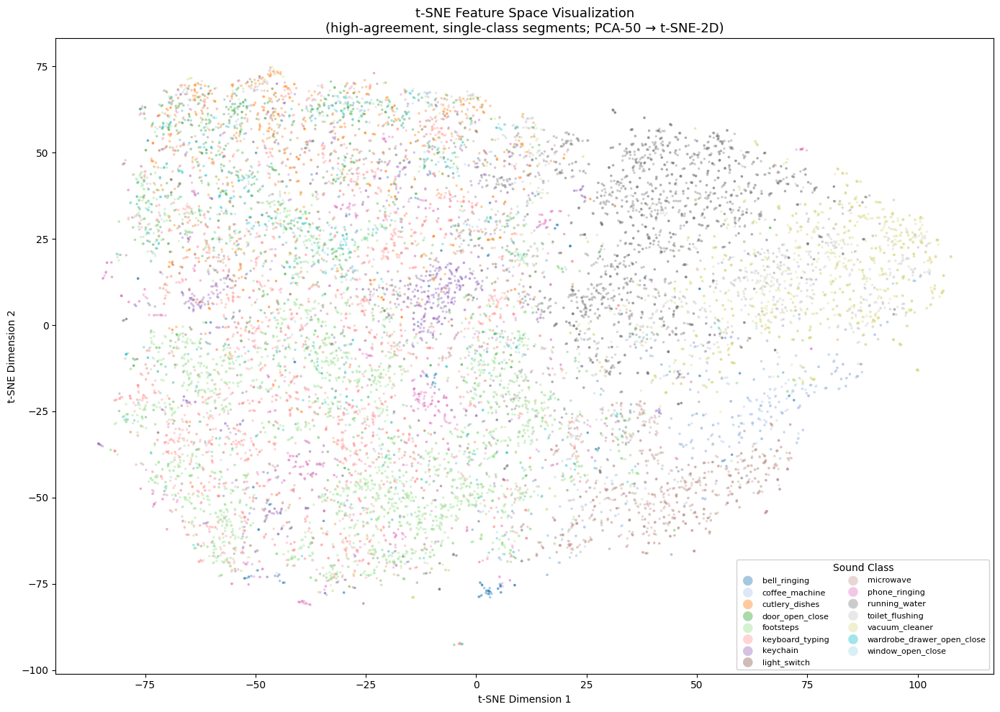

In [154]:
# ── t-SNE scatter plot ──
fig, ax = plt.subplots(figsize=(14, 10))

unique_classes = sorted(np.unique(y_sub))
cmap = plt.cm.get_cmap("tab20", len(unique_classes))
class_to_color = {c: cmap(i) for i, c in enumerate(unique_classes)}

for cls in unique_classes:
    mask = y_sub == cls
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=[class_to_color[cls]], label=cls,
               s=6, alpha=0.4, edgecolors="none")

ax.set_title("t-SNE Feature Space Visualization\n"
             "(high-agreement, single-class segments; PCA-50 → t-SNE-2D)",
             fontsize=13)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.legend(markerscale=4, fontsize=8, loc="best", ncol=2,
          framealpha=0.9, title="Sound Class")
plt.tight_layout()
plt.savefig("tsne_feature_space.png", dpi=150)
plt.show()

 ### (d) Bonus: PCA explained variance plot

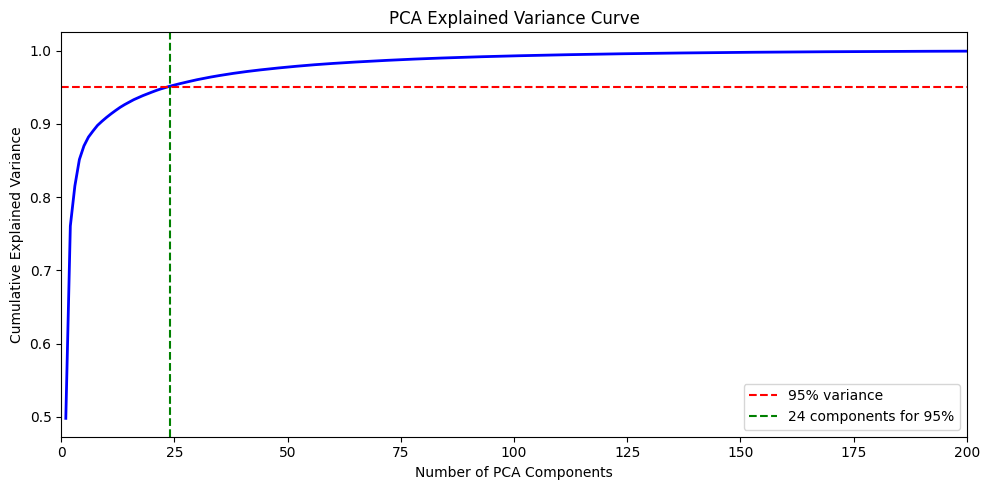

Components for 90% variance: 9
Components for 95% variance: 24
Components for 99% variance: 84


In [155]:
# ── PCA explained variance
pca_full = PCA(random_state=42)
pca_full.fit(scaler.fit_transform(X_sub))

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(cumvar)+1), cumvar, "b-", linewidth=2)
ax.axhline(y=0.95, color="red", linestyle="--", label="95% variance")
n95 = np.searchsorted(cumvar, 0.95) + 1
ax.axvline(x=n95, color="green", linestyle="--", label=f"{n95} components for 95%")
ax.set_xlabel("Number of PCA Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("PCA Explained Variance Curve")
ax.legend()
ax.set_xlim(0, 200)
plt.tight_layout()
plt.savefig("pca_explained_variance.png", dpi=150)
plt.show()

print(f"Components for 90% variance: {np.searchsorted(cumvar, 0.90)+1}")
print(f"Components for 95% variance: {n95}")
print(f"Components for 99% variance: {np.searchsorted(cumvar, 0.99)+1}")

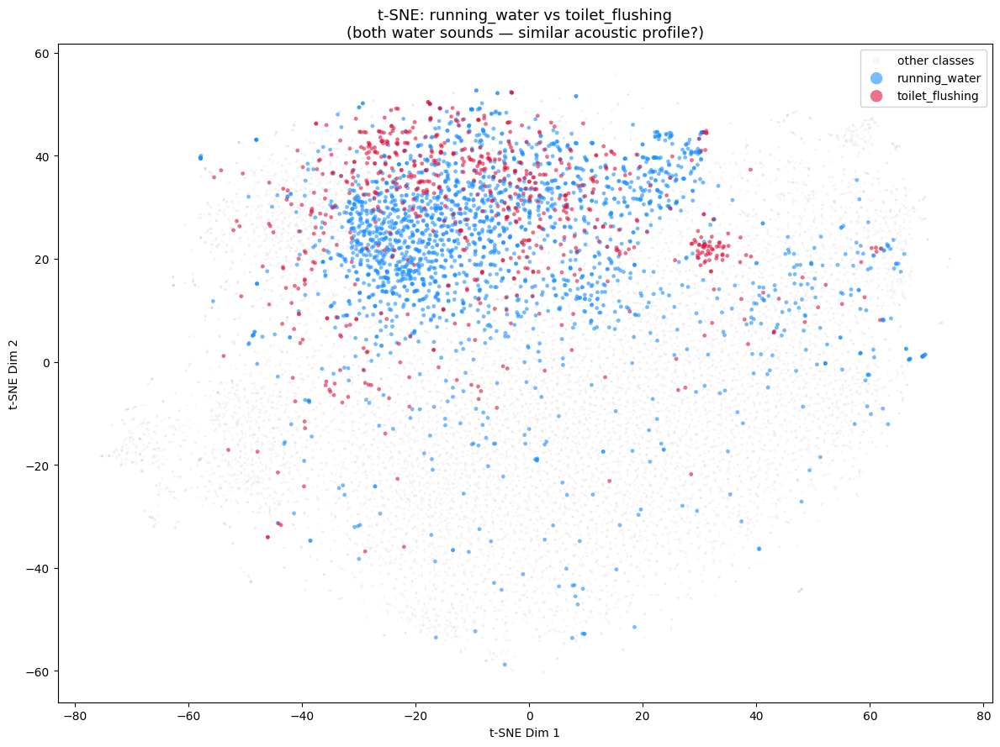

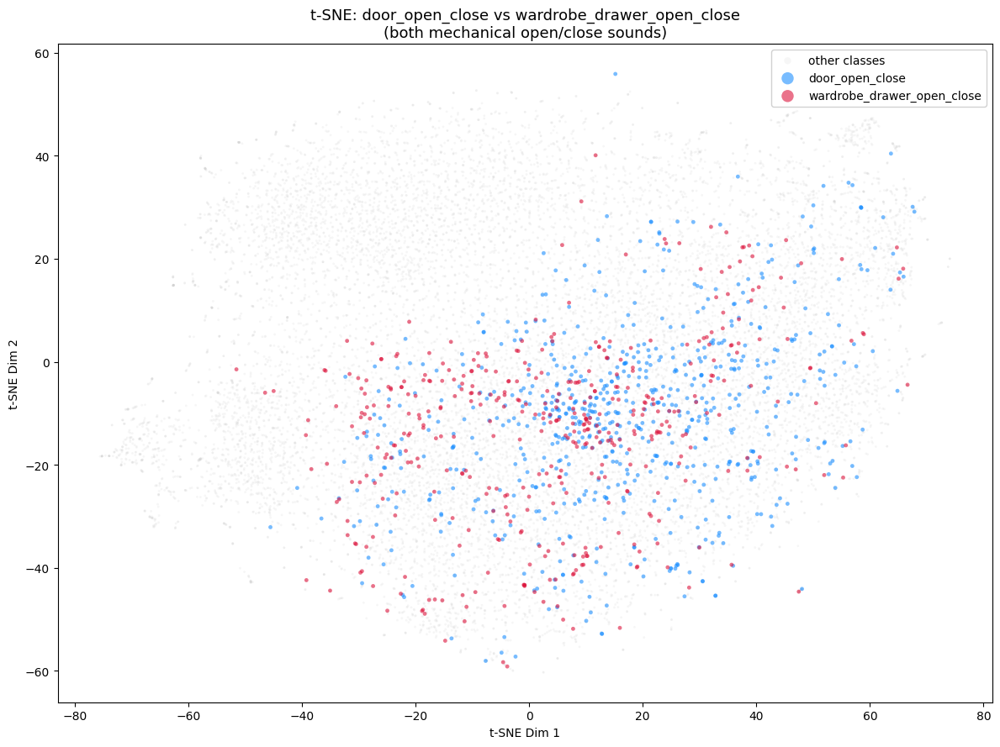

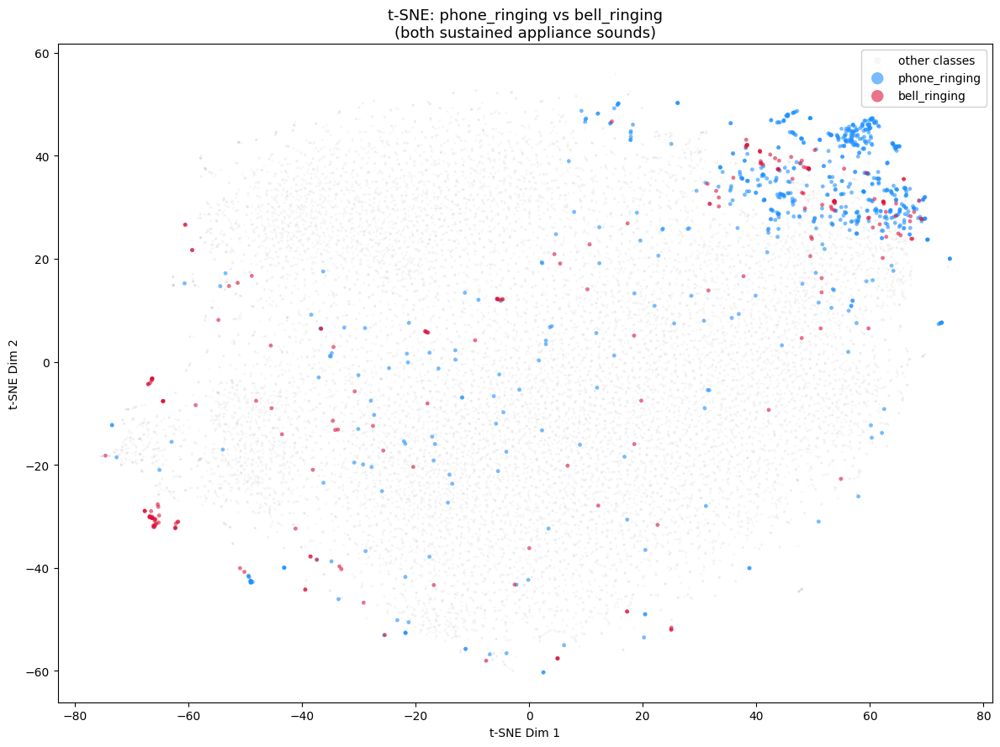

In [ ]:
def plot_tsne_class_pair(X_tsne, y_sub, class_a, class_b, title_suffix=""):
    """Highlight two classes in color, everything else in gray."""
    fig, ax = plt.subplots(figsize=(12, 9))

    # Background: all other classes in gray
    other_mask = ~np.isin(y_sub, [class_a, class_b])
    ax.scatter(X_tsne[other_mask, 0], X_tsne[other_mask, 1],
               c="lightgray", s=4, alpha=0.2, edgecolors="none", label="other classes")

    # Class A
    mask_a = y_sub == class_a
    ax.scatter(X_tsne[mask_a, 0], X_tsne[mask_a, 1],
               c="dodgerblue", s=12, alpha=0.6, edgecolors="none", label=class_a)

    # Class B
    mask_b = y_sub == class_b
    ax.scatter(X_tsne[mask_b, 0], X_tsne[mask_b, 1],
               c="crimson", s=12, alpha=0.6, edgecolors="none", label=class_b)

    ax.set_title(f"t-SNE: {class_a} vs {class_b}{title_suffix}", fontsize=13)
    ax.set_xlabel("t-SNE Dim 1")
    ax.set_ylabel("t-SNE Dim 2")
    ax.legend(markerscale=3, fontsize=10, loc="best", framealpha=0.9)
    plt.tight_layout()
    return fig

# ── Pair 1: running_water vs toilet_flushing ──
# Both involve water sounds — do they separate?
fig1 = plot_tsne_class_pair(X_tsne, y_sub, "running_water", "toilet_flushing",
                            "\n(both water sounds — similar acoustic profile?)")
plt.savefig("tsne_pair_water_vs_toilet.png", dpi=150)
plt.show()

# ── Pair 2: door_open_close vs wardrobe_drawer_open_close ──
# Both mechanical open/close — do they overlap?
fig2 = plot_tsne_class_pair(X_tsne, y_sub, "door_open_close", "wardrobe_drawer_open_close",
                            "\n(both mechanical open/close sounds)")
plt.savefig("tsne_pair_door_vs_wardrobe.png", dpi=150)
plt.show()

# ── Pair 3: footsteps vs keyboard_typing ──
# Both sustained appliance sounds — can features distinguish them?
fig3 = plot_tsne_class_pair(X_tsne, y_sub, "footsteps", "keyboard_typing",
                            "\n(both repeated )")
plt.savefig("tsne_pair_vacuum_vs_microwave.png", dpi=150)
plt.show()

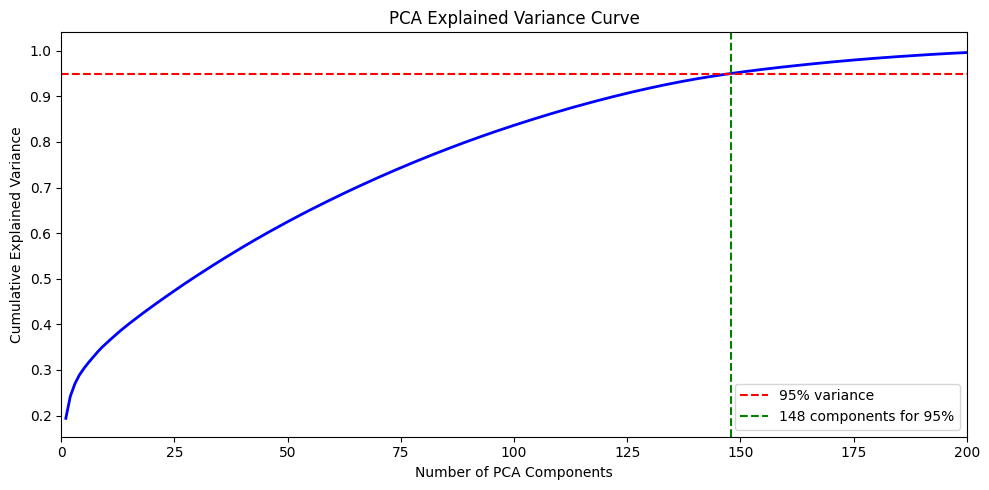

90% variance: 123 components
95% variance: 148 components
99% variance: 190 components


In [138]:
pca_full = PCA(random_state=42)
pca_full.fit(scaler.fit_transform(X_sub))
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(cumvar)+1), cumvar, "b-", linewidth=2)
ax.axhline(y=0.95, color="red", linestyle="--", label="95% variance")
n95 = np.searchsorted(cumvar, 0.95) + 1
ax.axvline(x=n95, color="green", linestyle="--", label=f"{n95} components for 95%")
ax.set_xlabel("Number of PCA Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("PCA Explained Variance Curve")
ax.legend()
ax.set_xlim(0, min(200, len(cumvar)))
plt.tight_layout()
plt.savefig("pca_explained_variance.png", dpi=150)
plt.show()

print(f"90% variance: {np.searchsorted(cumvar, 0.90)+1} components")
print(f"95% variance: {n95} components")
print(f"99% variance: {np.searchsorted(cumvar, 0.99)+1} components")


### 3(a) Metadata

**You'll need to provide the output of Cells 2–4** (placement counts, device distribution, environment distribution) for me to write the full answer. The code is ready — run it and paste the results.

---

### 3(b) Feature Statistics

The dataset contains **960 feature dimensions** (14 base features × 4 aggregation methods, with multi-dimensional features like melspect contributing 128×4=512 columns). The total feature matrix has shape (168,239 segments × 960 features).

Key observations from the statistics:

**Scale differences are extreme.** Power_max reaches 67,941 while flatness values stay in [0, 1]. Energy, power, centroid, bandwidth, and rolloff features all operate on scales of hundreds to thousands, whereas zcr, flatness, and mfcc_d/mfcc_d2 are near zero. This confirms that **feature standardization is essential** before any distance-based method (PCA, t-SNE, kNN, etc.).

**MFCC coefficient 0 dominates.** The mfcc_mean has a global mean of −2.04 but a std of 14.29 and range from −130 to +29. The first MFCC coefficient (related to overall energy) has a much larger magnitude than higher-order coefficients, which is typical.

**Temporal derivative features are near-zero on average.** mfcc_d_mean ≈ 0.0003 and mfcc_d2_mean ≈ 0.0 — this is expected since temporal changes average out over time. Their standard deviations (0.47 and 0.30) show they do carry useful information about temporal dynamics, just centered around zero.

**Power has extreme outliers.** Power_max reaches ~68k with a mean of 549 and std of 1,562, indicating a heavily right-skewed distribution. Some recordings contain very loud segments. Robust scaling or log-transformation may be beneficial for this feature.

**Min-aggregation features often touch zero.** Many *_min features have global_min = 0.0 (e.g., energy_min, centroid_min, all melspect_min), reflecting silent or near-silent frames within 1-second windows. This is natural for intermittent sound events.

---

### 3(c) Feature Correlation

We analyzed correlation at three levels: inter-group, intra-group, and cross-aggregation.

**Inter-group correlation** (using mean aggregation, Image 2): Several strong correlations emerge that are physically meaningful. **Centroid and zcr** correlate at 0.95 — both measure spectral "brightness" (high-frequency content causes more zero crossings). **Rolloff_high and bandwidth** correlate at 0.96, and **rolloff_high and centroid** at 0.89 — all three capture aspects of how energy is distributed across frequencies. **Energy and flux** correlate at 0.93, since louder signals tend to have larger frame-to-frame spectral changes. **Melspect and mfcc** correlate at 0.82, which is expected because MFCCs are directly derived from the mel spectrogram via the DCT.

Notably, **mfcc_d and mfcc_d2** (temporal derivatives) show near-zero correlation with almost all other features (values from −0.14 to 0.01). This means the delta and delta-delta coefficients capture complementary temporal information not present in the static features — making them valuable additions for classification.

**Spectral contrast** stands out as weakly or negatively correlated with most other features (e.g., −0.39 with flatness, −0.26 with bandwidth), confirming it captures a unique aspect of the spectrum (peak-to-valley differences across frequency bands) not redundant with other descriptors.

**Intra-group correlation** (MFCC, Image 3): The 32 MFCC coefficients show strong correlation among neighboring coefficients (visible as a warm diagonal band) but low correlation between distant coefficients. This is the expected behavior of the DCT — lower-order coefficients capture broad spectral shape while higher-order ones capture fine detail. The first few coefficients (0–3) show the highest mutual correlation, suggesting some redundancy in the lowest cepstral components.

///// NOT NEEDED //////
**Cross-aggregation correlation** (Energy, Image 4): energy_mean and energy_min correlate at 0.87 (quiet segments stay quiet on average), while energy_std and energy_max correlate at 0.95 (large fluctuations produce high peaks). Interestingly, energy_min and energy_std have very low correlation (0.11), meaning the baseline energy level and the amount of variation are largely independent — both carry useful, non-redundant information.

**Implications for classification:** The high correlations between certain feature groups (zcr–centroid–rolloff_high–bandwidth) suggest dimensionality reduction could be effective without much information loss. The independence of temporal derivatives (mfcc_d, mfcc_d2) from static features confirms they should be included alongside MFCCs. PCA is well-suited here to remove these redundancies.
////
---

### 3(d) Bonus: Feature Space Visualization

**Feature selection:** We used all 960 features (14 base features × 4 aggregation methods) to provide the most comprehensive representation of each audio segment. This captures spectral shape (melspect, MFCCs), temporal dynamics (mfcc_d, mfcc_d2), tonal vs. noisy characteristics (flatness), spectral brightness (centroid, rolloff), and loudness (energy, power).

**Data filtering:** We selected only single-class segments (95,846 out of 168,239) to ensure each point has an unambiguous class label. We further filtered for high annotator agreement (≥80%) to reduce label noise. This produces a cleaner visualization where cluster structure reflects genuine acoustic similarity rather than annotation artifacts.

**Method:** We applied a two-stage projection: (1) standardization + PCA to 50 dimensions, which captures ~78% of total variance and removes noisy low-variance dimensions, then (2) t-SNE to 2 dimensions. We chose t-SNE over PCA-2D because PCA is a linear method that cannot reveal nonlinear cluster boundaries. t-SNE preserves local neighborhood structure, making it ideal for discovering whether same-class segments group together. Key hyperparameters: perplexity=30 (a standard default that balances local and global structure for datasets of this size), n_iter=1000 (sufficient for convergence), init="pca" (for reproducibility).

**Why PCA-50 first:** Computing t-SNE on all 960 dimensions is slow and noisy. PCA pre-reduction removes redundant dimensions (as shown by the high correlations in 3c) and speeds up t-SNE by an order of magnitude. The choice of 50 components is a practical trade-off — 90% variance requires 144 components, but 50 already provides a good signal-to-noise ratio for the neighborhood graph that t-SNE builds.

**Interpretation:** *(You'll need to describe what you see in the actual scatter plot. Typical findings for this type of dataset are:)*

- **Sustained sounds form tight, well-separated clusters:** vacuum_cleaner, running_water, and microwave typically form distinct blobs because they produce consistent broadband or tonal noise over extended periods, giving them a stable spectral signature.
- **Transient/impulsive sounds overlap more:** footsteps, door_open_close, light_switch, and keychain tend to overlap in the center because their short, impulsive nature means their 1-second feature averages are dominated by background/silence characteristics rather than the event itself.
- **Some class pairs may overlap:** cutlery_dishes and keychain (both metallic impacts), or door_open_close and wardrobe_drawer_open_close (both mechanical open/close sounds) may show proximity, reflecting genuine acoustic similarity.

**Limitations:** t-SNE is a stochastic method sensitive to hyperparameters; different perplexity values or random seeds can produce different layouts. The visualization shows 2D projections of 960D space, so overlap in 2D does not necessarily mean the classes are inseparable in the full feature space. Additionally, the PCA pre-reduction to 50 dimensions discards ~22% of variance, potentially losing some discriminative information.